In [3]:
.libPaths("~/R/x86_64-pc-linux-gnu-library/4.4/")

library(Seurat)
library(SeuratDisk)
library(patchwork)
library(harmony)
library(reshape2)
library(RColorBrewer)
library(dplyr)
library(readr)
library(tidyverse)
library(Matrix)
library(Seurat)
library(ggplot2)
library(cowplot)
library(celldex)
library(SingleR)
library(data.table)
library(scGate)
library(ggpubr)
library(scCustomize)

ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}


Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built with package ‘Matrix’ 1.7.4 but the current
version is 1.7.6; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


Registered S3 method overwritten by 'SeuratDisk':
  method            from  
  as.sparse.H5Group Seurat

Loading required package: Rcpp


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.0     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts()

# Processing 3p data T cells

We will load the Seurat object which contains data from T+NK cells from the 3p datasets after filtering. 

In [1]:
gut_3p_integrated <- readRDS("../241201_VN_PREDICT2/gut_3p_integrated_with_healthy_filt_without_ilc_v2.rds")

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



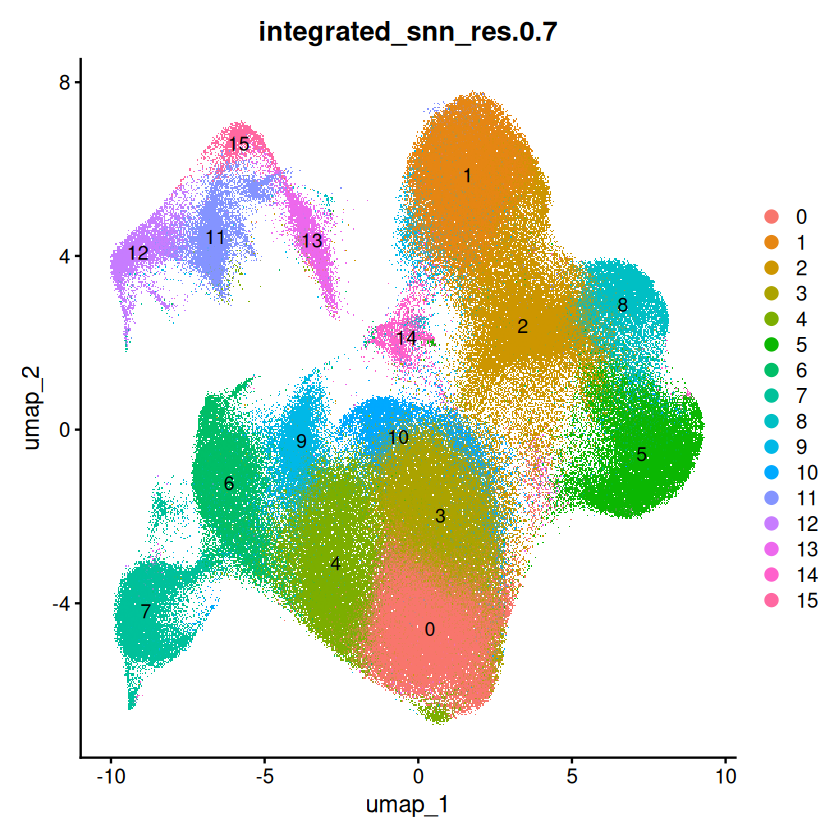

In [4]:
DimPlot(gut_3p_integrated, label = T, group.by = "integrated_snn_res.0.7")

Recode cluster numbers to annotations.

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



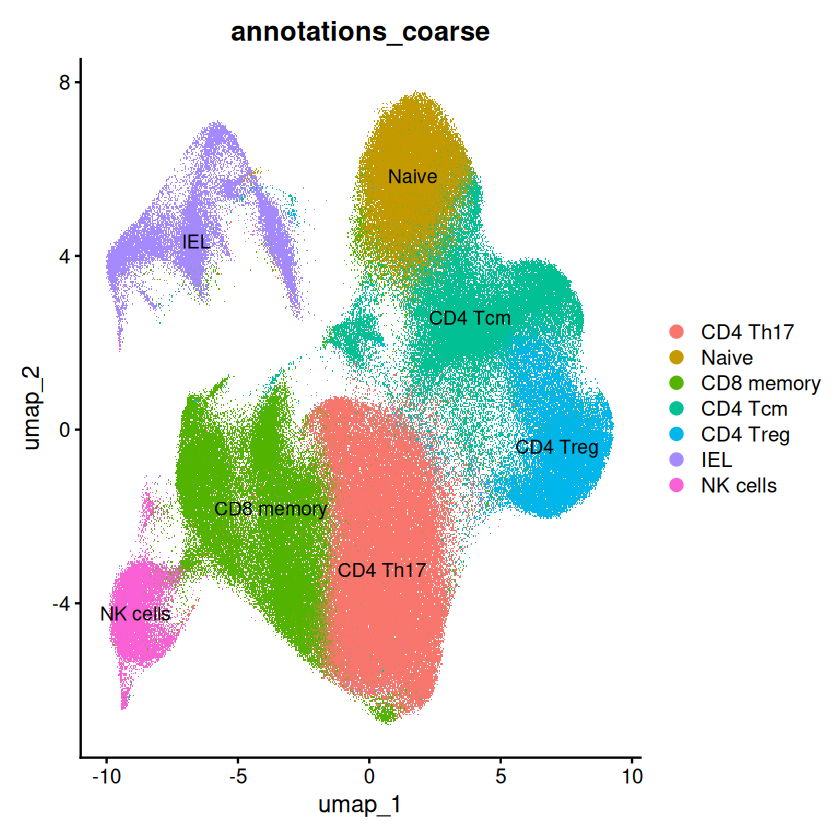

In [5]:
gut_3p_integrated@meta.data <- gut_3p_integrated@meta.data  %>% mutate(annotations_coarse = 
                                                                       recode_factor(integrated_snn_res.0.3, 
"0" = "CD4 Th17",                                                                         
"1" = "Naive",
"2" = "CD8 memory",
"3" = "CD4 Tcm",
"4" = "CD4 Treg",
"5" = "CD8 memory",
"6" = "IEL",
"7" = "NK cells",
"8" = "CD4 Tcm",
"9" = "CD4 Th17",
"10" = "IEL"))

DimPlot(gut_3p_integrated, group.by = "annotations_coarse", label = T)

For visualization purposes we will turn the UMAP plot so that the cluster position is similar to that of 5p data. 

In [8]:
gut_allt_3p  <- gut_3p_integrated

In [9]:
gut_allt_3p@reductions$umap@cell.embeddings[,1]  <- -1*gut_allt_3p@reductions$umap@cell.embeddings[,1]

In [10]:
gut_allt_3p@reductions$umap@cell.embeddings[,2]  <- -1*gut_allt_3p@reductions$umap@cell.embeddings[,2]

We will add cluster annotations. 

In [11]:
gut_allt_3p@meta.data <- gut_allt_3p@meta.data  %>% mutate(annotations_coarse = 
                                                                       recode_factor(integrated_snn_res.0.3, 
"0" = "CD4 Th17",                                                                         
"1" = "Naive",
"2" = "CD8 and Tgd",
"3" = "CD4 Tcm",
"4" = "CD4 Treg",
"5" = "CD8 and Tgd",
"6" = "CD8 and Tgd",
"7" = "NK cells",
"8" = "CD4 Tcm",
"9" = "CD4 Th17",
"10" = "CD8 and Tgd"))

In [12]:
pallete  <- c("Naive" = "#b288d9ff",
              "CD4 Tcm" = "#d9a988ff",
              "CD4 Th17" = "#b1d988ff",
              "CD4 Treg" = "#f0c963ff",
              "CD8 and Tgd" = "#88d9c4ff",
              "IEL" = "#88b8d9ff",
              "NK cells" = "#88b8d8ff")

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



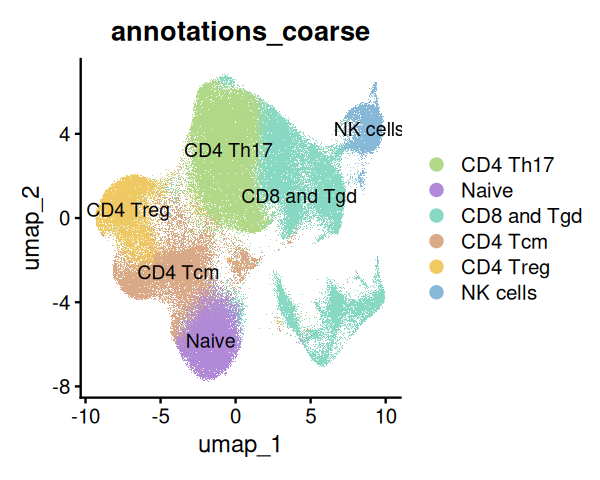

In [13]:
options(repr.plot.width = 5, repr.plot.height = 4)
DimPlot(gut_allt_3p, group.by = "annotations_coarse", label = T, cols = pallete)

In [14]:
gut_allt_3p$patient  %>% table

.
HE-001-014 HE-001-023 HE-001-024 HE-001-025 HE-001-026       p002       p003 
      2298       2577       1325        859       2675       3821       6742 
      p009       p010       p011       p014       p015       p016       p017 
      9784       6734      12681       5315      12283       4201       3121 
      p018       p019       p020       p021       p022       p023       p024 
     13058      16121       8566       8792       3891       5355       6450 
      p025       p026       p027       p028       p030       p031       p032 
      7739       7777       9538       6434       7615       6011       7268 
      p033       p034       p035       p036       p037       p038       p040 
      6255       4005       3750       8002       6118       4087       4427 
      p041       p042       p043       p044       p045       p047       p048 
      7048       9608       5818       6194       5469       4206       6101 
      p049       p050 
      6753       6405 

# Subset of CD4 cells 3p

Next we will subset only CD4 T cells for downstream analysis. 

We will first check CD8A and CD4 expression in coarse versus fine clusters. 

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



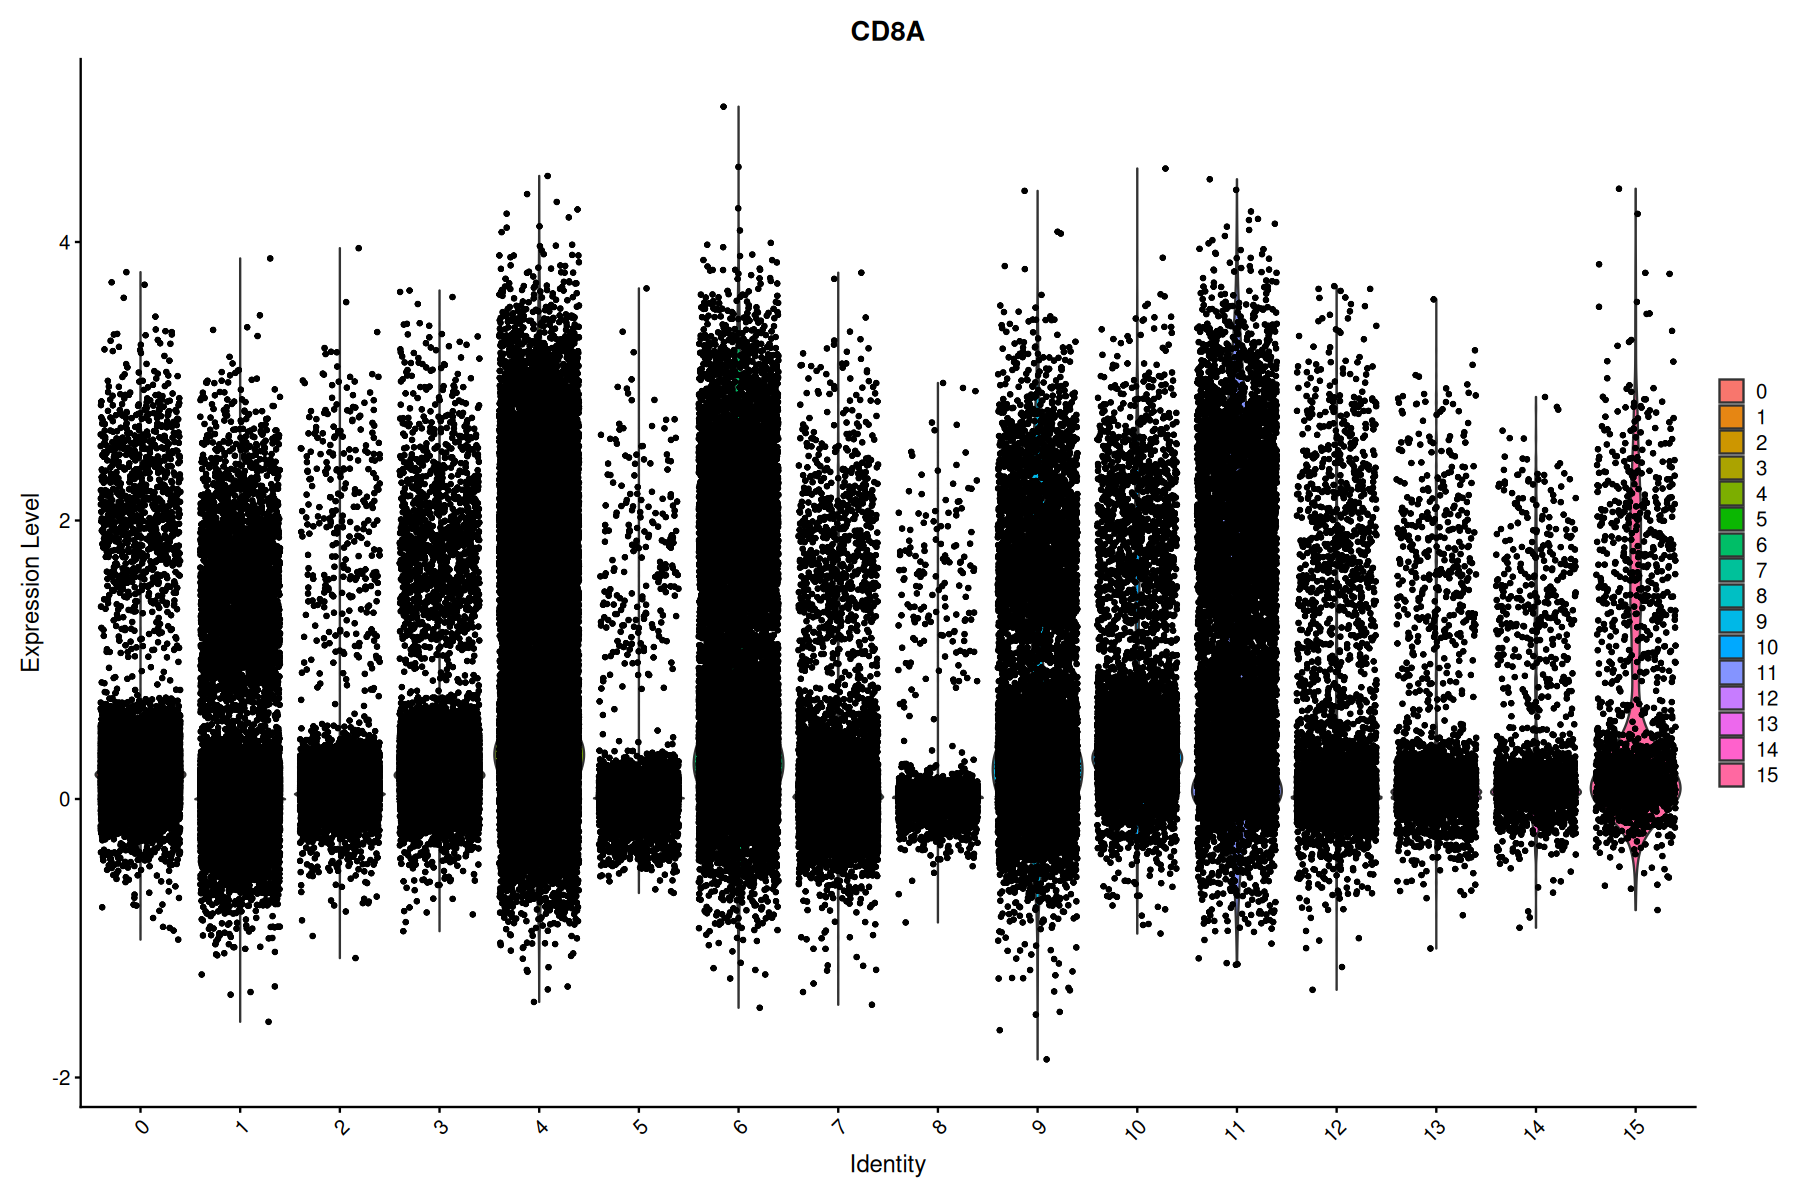

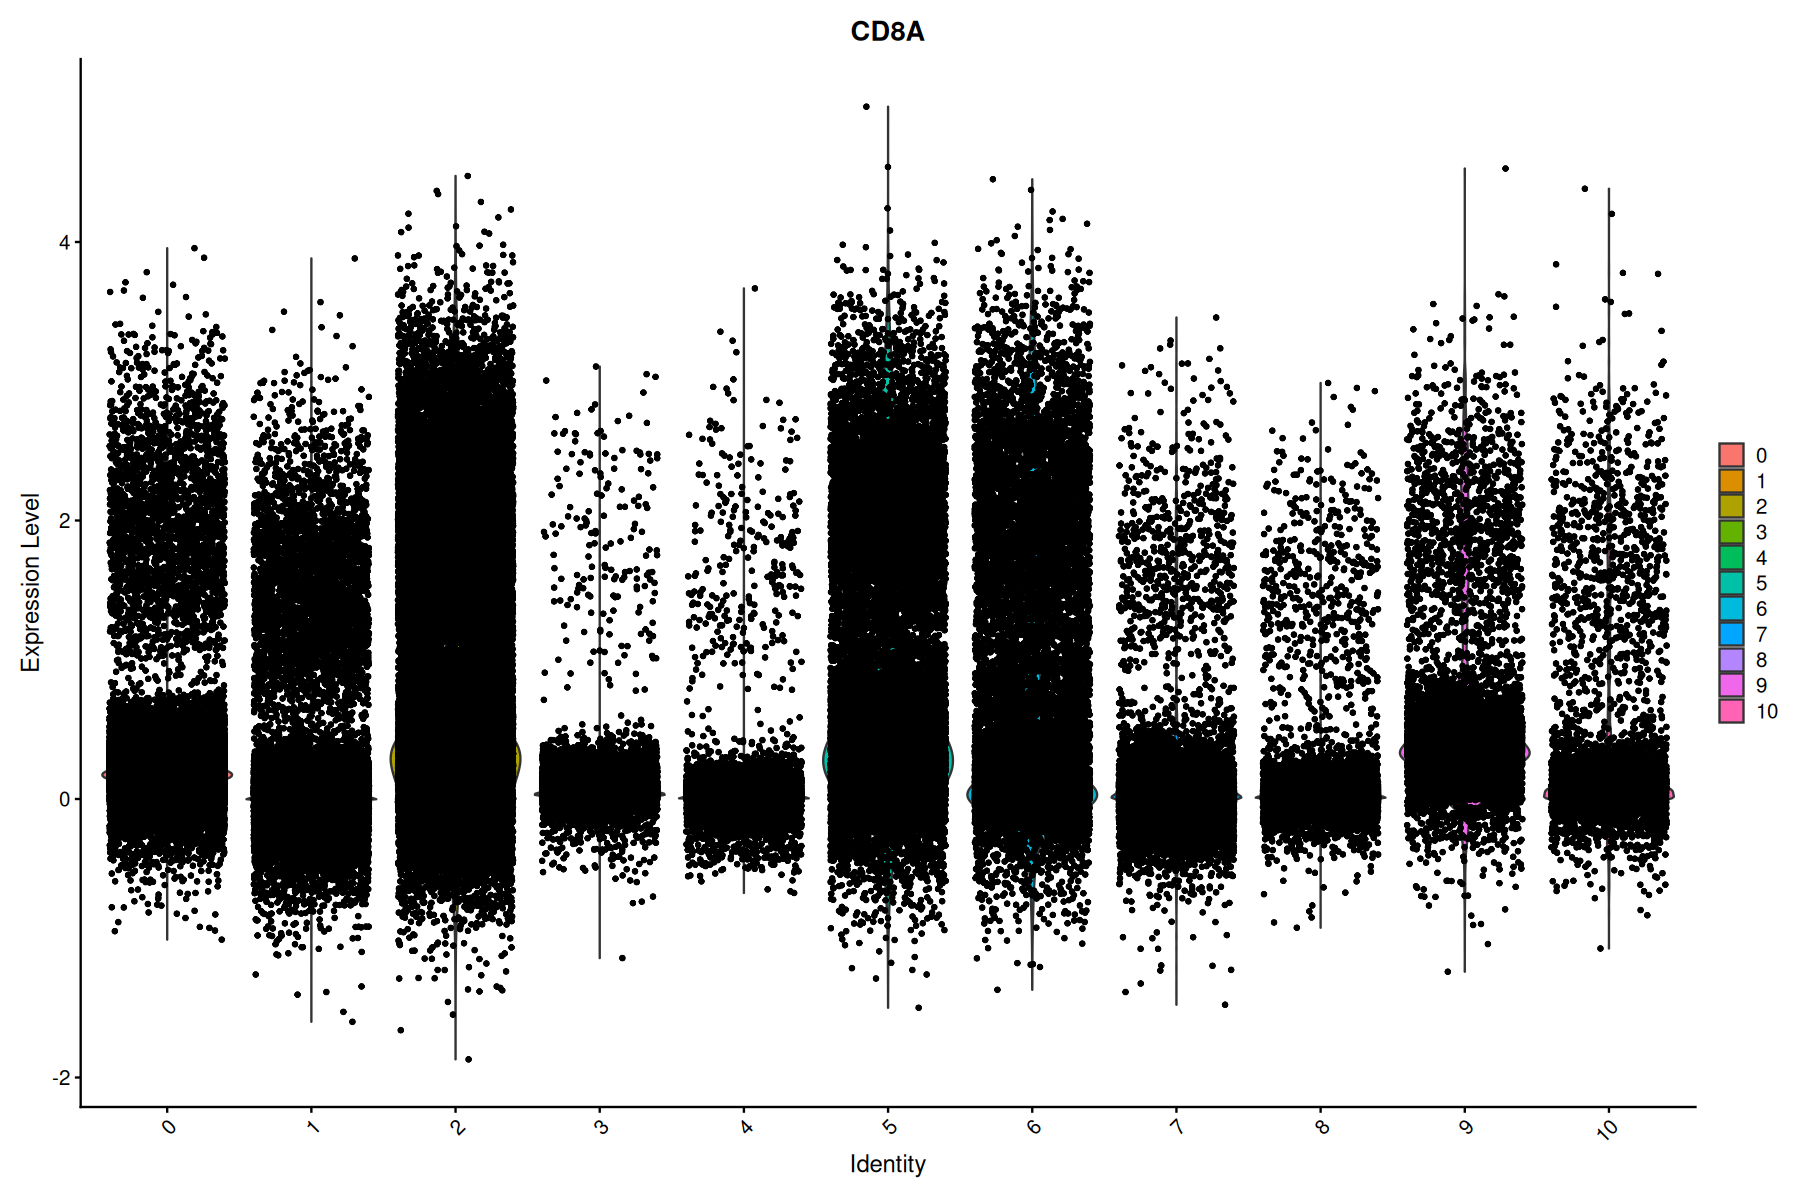

In [104]:
VlnPlot(gut_3p_integrated, group.by = "integrated_snn_res.0.7", features = "CD8A")
VlnPlot(gut_3p_integrated, group.by = "integrated_snn_res.0.3", features = "CD8A")

Warning message:
“Could not find CD4 in the default search locations, found in ‘RNA’ assay instead”
Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Warning message:
“Could not find CD4 in the default search locations, found in ‘RNA’ assay instead”
Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



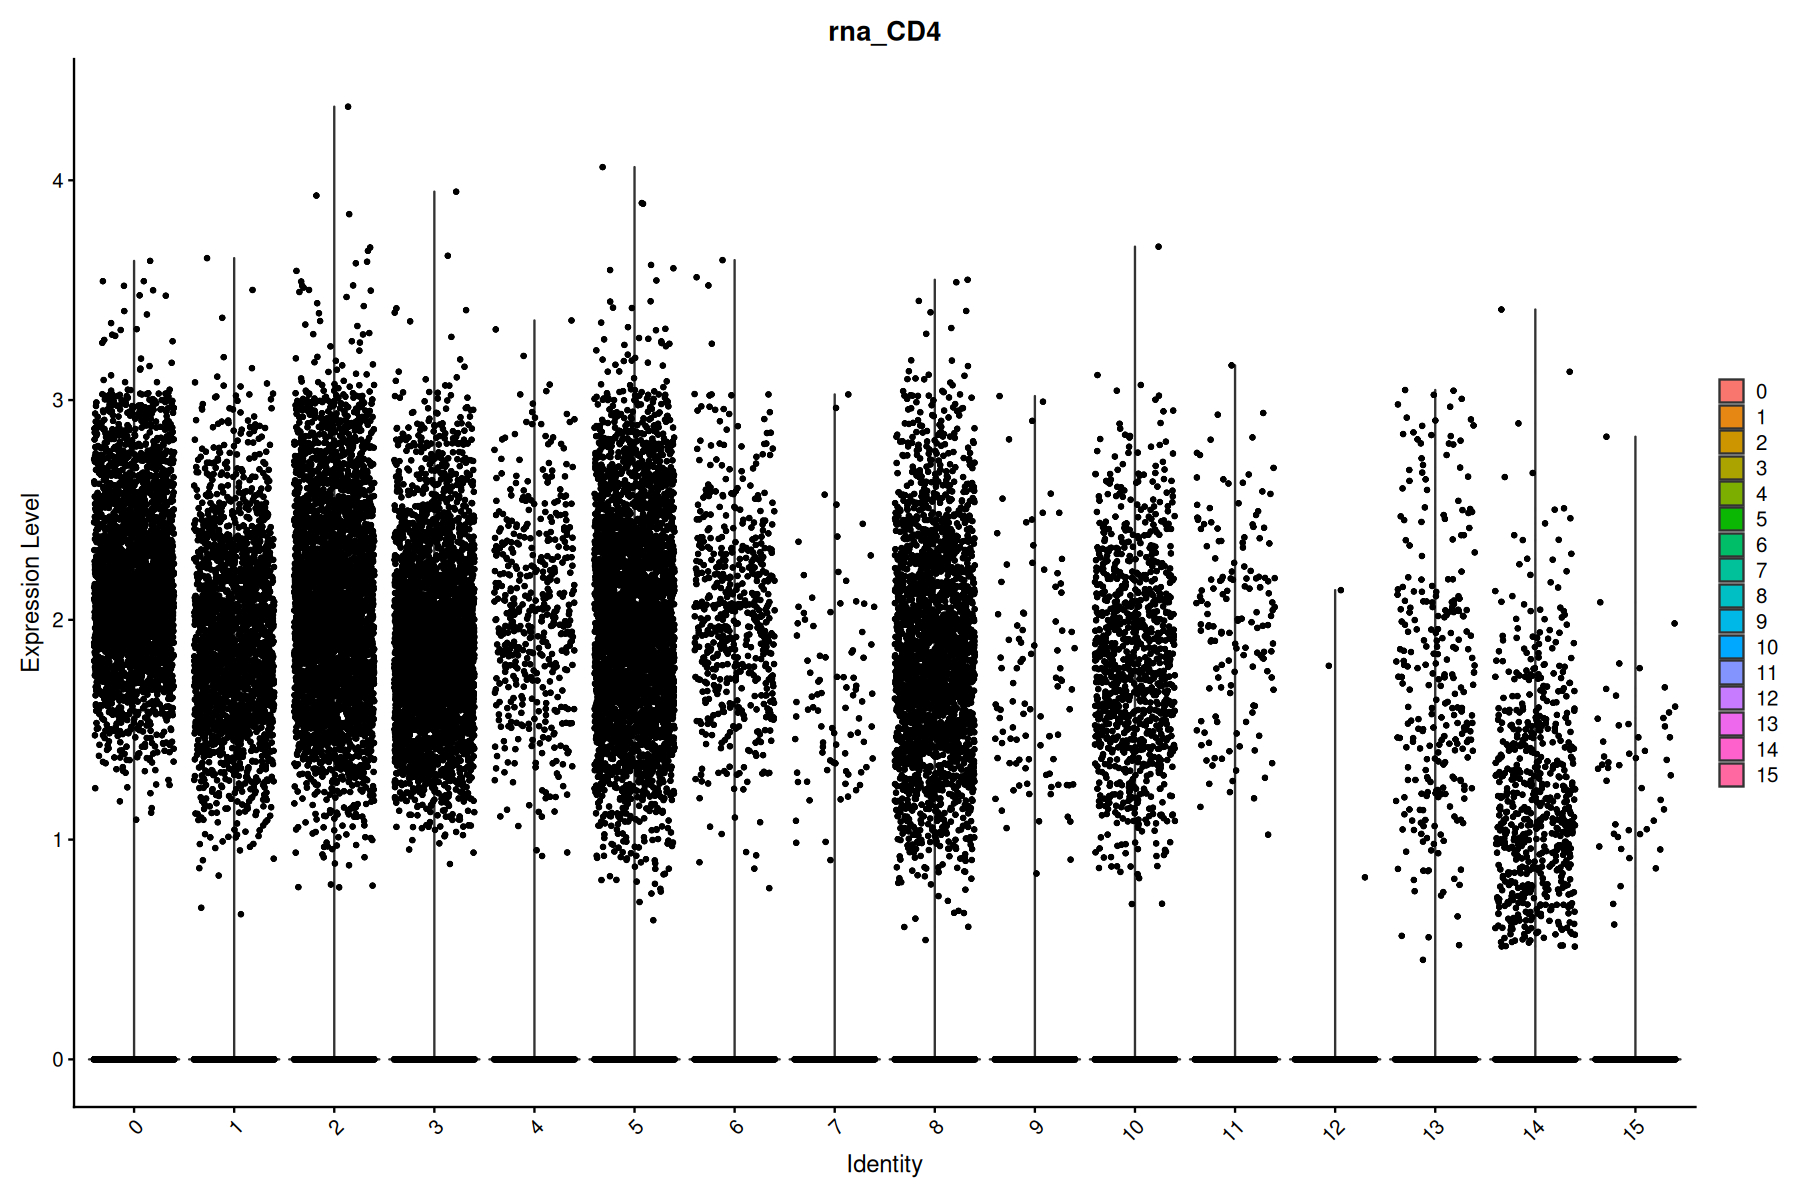

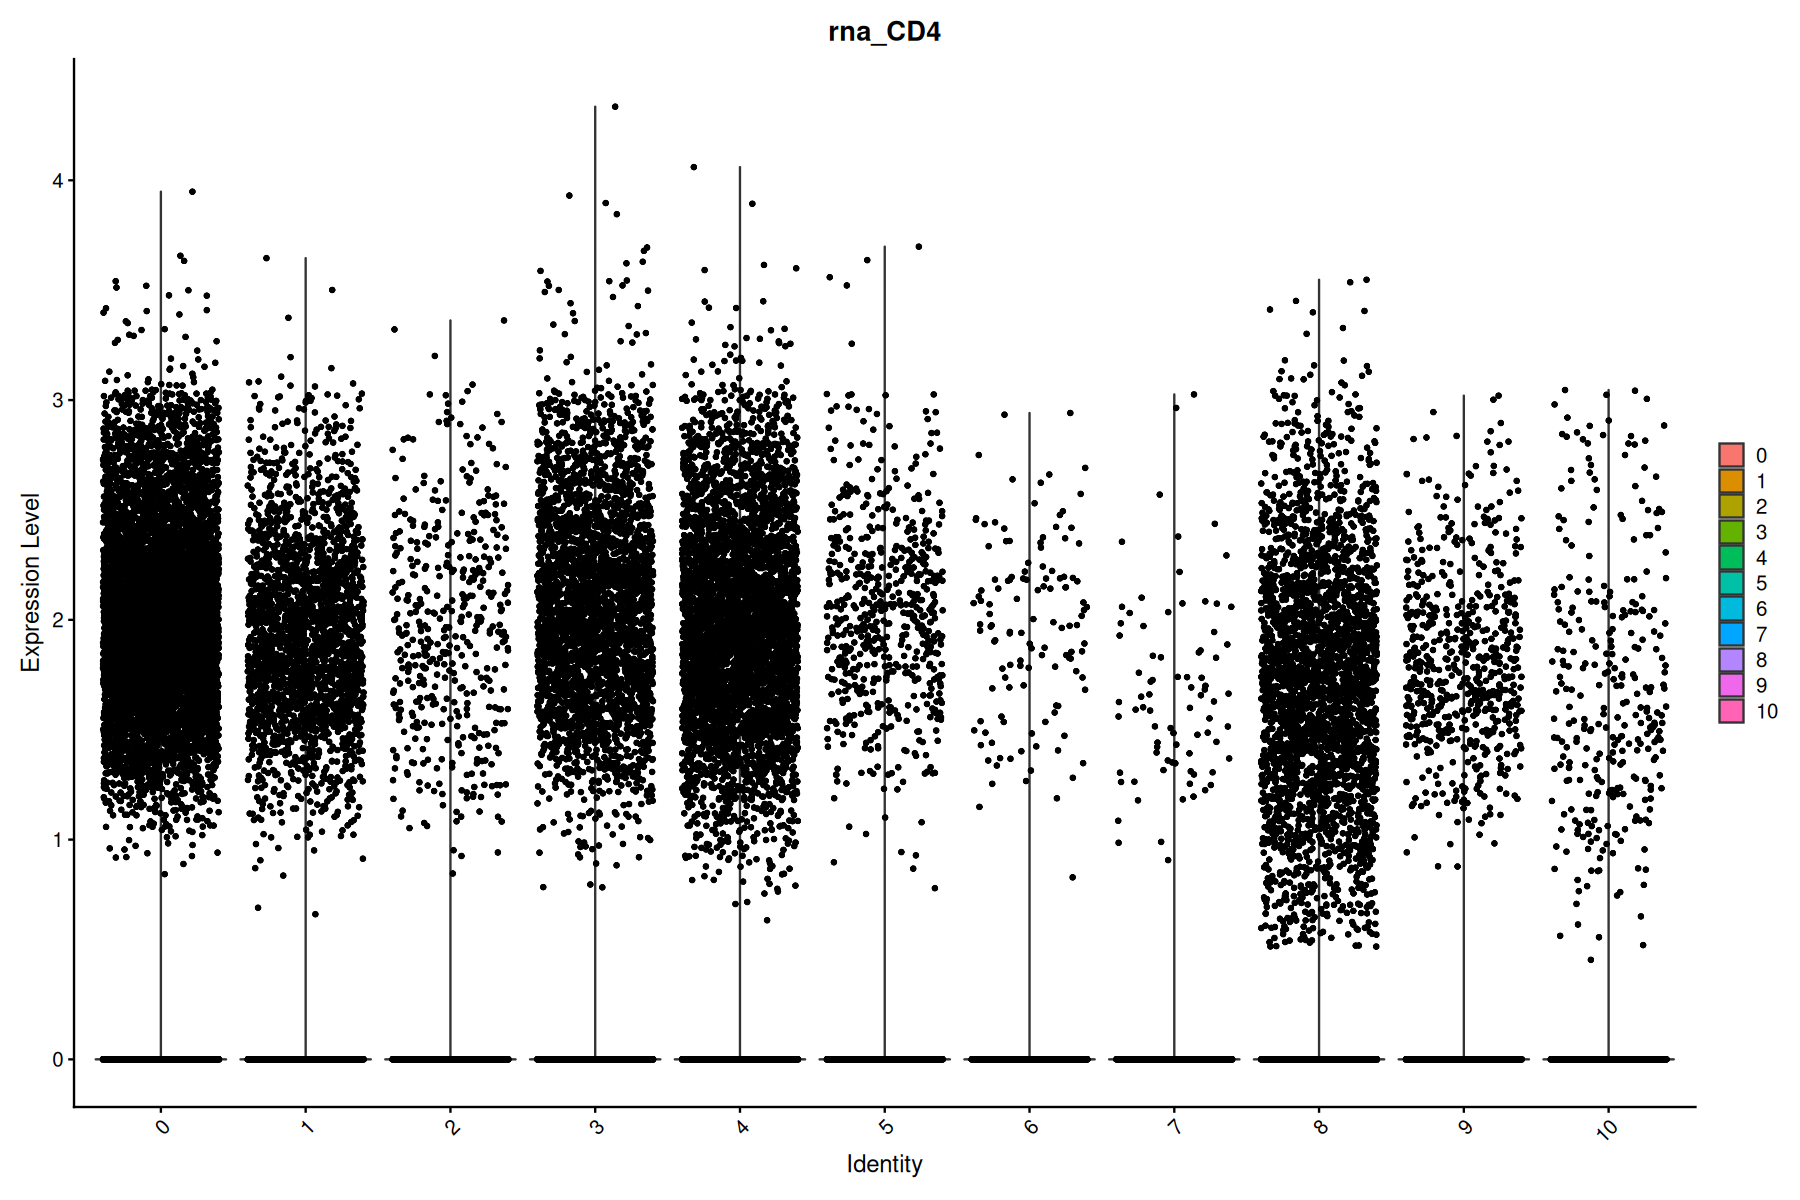

In [103]:
VlnPlot(gut_3p_integrated, group.by = "integrated_snn_res.0.7", features = "CD4")
VlnPlot(gut_3p_integrated, group.by = "integrated_snn_res.0.3", features = "CD4")

## Is CD4 or CD8 by expression

Next, we will label cells which have nonzero expression of CD8, CD8A and CD8B.

In [30]:
which(rownames(gut_3p_integrated@assays$RNA) == "CD4")

[1] 9676

In [31]:
which(rownames(gut_3p_integrated@assays$RNA) == "CD8A")

[1] 2077

In [32]:
which(rownames(gut_3p_integrated@assays$RNA) == "CD8B")

[1] 2078

In [33]:
gut_3p_integrated$cd4  <- ifelse(gut_3p_integrated@assays$RNA@counts[9676,]>0,1,0)

In [34]:
table(gut_3p_integrated$cd4)


     0      1 
260580  22697 

In [35]:
gut_3p_integrated$cd8  <- ifelse(gut_3p_integrated@assays$RNA@counts[2077,]>0|
                                 gut_3p_integrated@assays$RNA@counts[2078,]>0,1,0)

In [36]:
table(gut_3p_integrated$cd8)


     0      1 
230733  52544 

In [37]:
gut_3p_integrated$cd4_or_cd8  <-  ifelse(gut_3p_integrated$cd4 == 1& gut_3p_integrated$cd8 == 0, "CD4",
                                        ifelse(gut_3p_integrated$cd4 == 0& gut_3p_integrated$cd8 == 1, "CD8",
                                        "Unknown"))

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



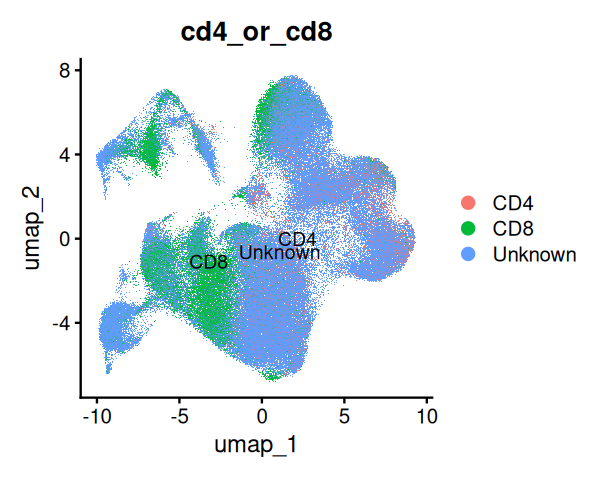

In [38]:
DimPlot(gut_3p_integrated, group.by = "cd4_or_cd8", label = T)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



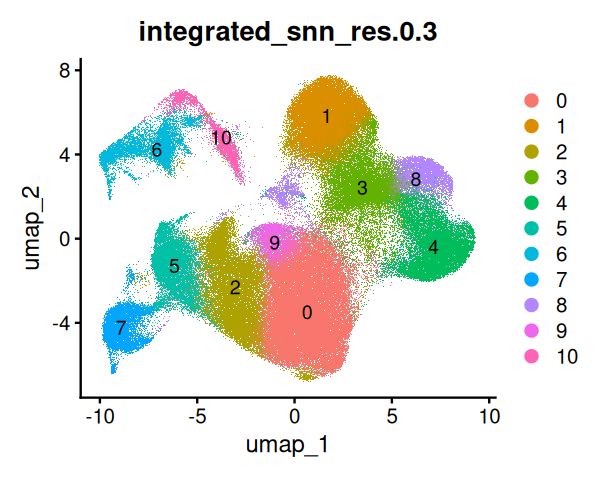

In [28]:
DimPlot(gut_3p_integrated, group.by = "integrated_snn_res.0.3", label = T)

We will take the unclear cells and asign them the CD4 or CD8 identity based on the cluster in which they are found. 

In [39]:
gut_3p_integrated$cd4_or_cd8_2  <-  ifelse(gut_3p_integrated$cd4_or_cd8 == "CD4", 'CD4',
                                        ifelse(gut_3p_integrated$cd4_or_cd8 == "CD8", "CD8",
                                        ifelse(gut_3p_integrated$integrated_snn_res.0.3 %in% c(0,1,3,4,8), "CD4",
                                               ifelse(gut_3p_integrated$integrated_snn_res.0.3 %in% c(2,5,6), "CD8","Other"))))

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



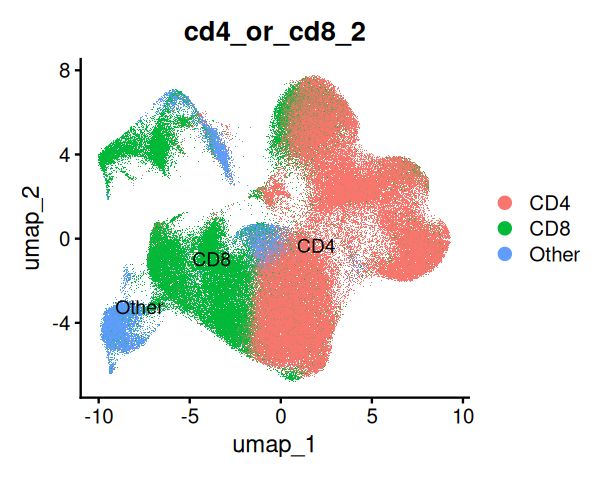

In [40]:
DimPlot(gut_3p_integrated, group.by = "cd4_or_cd8_2", label = T)

## Subset and reintegration

We will subset only CD4 T cells and reintegrate it with STACAS. 

In [41]:
cd4_3p  <- subset(gut_3p_integrated, cd4_or_cd8_2 == "CD4")

In [42]:
cd4_3p

An object of class Seurat 
28494 features across 175466 samples within 2 assays 
Active assay: integrated (1000 features, 1000 variable features)
 2 layers present: data, scale.data
 1 other assay present: RNA
 2 dimensional reductions calculated: pca, umap

In [43]:
cd4_3p$patient  %>% table

.
HE-001-014 HE-001-023 HE-001-024 HE-001-025 HE-001-026       p002       p003 
      1526       1604        356        391       1911       2252       3243 
      p009       p010       p011       p014       p015       p016       p017 
      7685       4784       8041       3468       8505       2820       1813 
      p018       p019       p020       p021       p022       p023       p024 
      7613       9448       5429       6265       2295       4253       4593 
      p025       p026       p027       p028       p030       p031       p032 
      5022       4330       6406       3881       4191       2916       4836 
      p033       p034       p035       p036       p037       p038       p040 
      4207       3052       1955       5712       2779       2876       3143 
      p041       p042       p043       p044       p045       p047       p048 
      4752       5963       3587       2850       2511       2832       2759 
      p049       p050 
      3379       3232 

In [44]:
library(STACAS)

In [45]:
merged_ds <- SplitObject(cd4_3p, split.by = "patient")
merged.list <- lapply(X = merged_ds, FUN = function(x) {
DefaultAssay(x)  <- "RNA"
x$barcode  <- colnames(x)
x <- NormalizeData(x)
x <- FindVariableFeatures(x, selection.method = "vst", nfeatures = 1000)
})

cd4_3p_int <- Run.STACAS(merged.list, dims = 1:15)
cd4_3p_int <- RunUMAP(cd4_3p_int, dims = 1:15) 
cd4_3p_int <- FindNeighbors(cd4_3p_int)
cd4_3p_int <- FindClusters(cd4_3p_int, res = c(0.3,0.5,0.7,0.9))

saveRDS(cd4_3p_int, "cd4_3p_int_with_healthy_filt_without_ilc_v2_just_cd4.rds")

Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“pseudoinverse used at -2.2504”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“neighborhood radius 0.30103”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“reciprocal condition number  2.7797e-16”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“pseudoinverse used at -2.2911”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“neighborhood radius 0.30103”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“reciprocal condition number  2.5794e-16”
Warning message:
“The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the STACAS package.
  Please report the issue to the authors.”
Warn

Warning message:
“Different cells and/or features from existing assay integrated”

Integrating dataset 29 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data

Warning message:
“Different cells and/or features from existing assay integrated”

Integrating dataset 30 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data

Warning message:
“Different cells and/or features from existing assay integrated”

Integrating dataset 31 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data

Warning message:
“Different cells and/or features from existing assay integrated”

Integrating dataset 33 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data

Warning message:
“Different cells and/or features from existing assay integrated”

Integrating dataset 34 with reference dataset

Finding integratio

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 175466
Number of edges: 3942354

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8963
Number of communities: 7
Elapsed time: 99 seconds
Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 175466
Number of edges: 3942354

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8646
Number of communities: 9
Elapsed time: 111 seconds
Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 175466
Number of edges: 3942354

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8375
Number of communities: 12
Elapsed time: 123 seconds
Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 175466
Number of edges: 3942354

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8147
Number of communities: 12
Elapsed time: 125 seconds

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



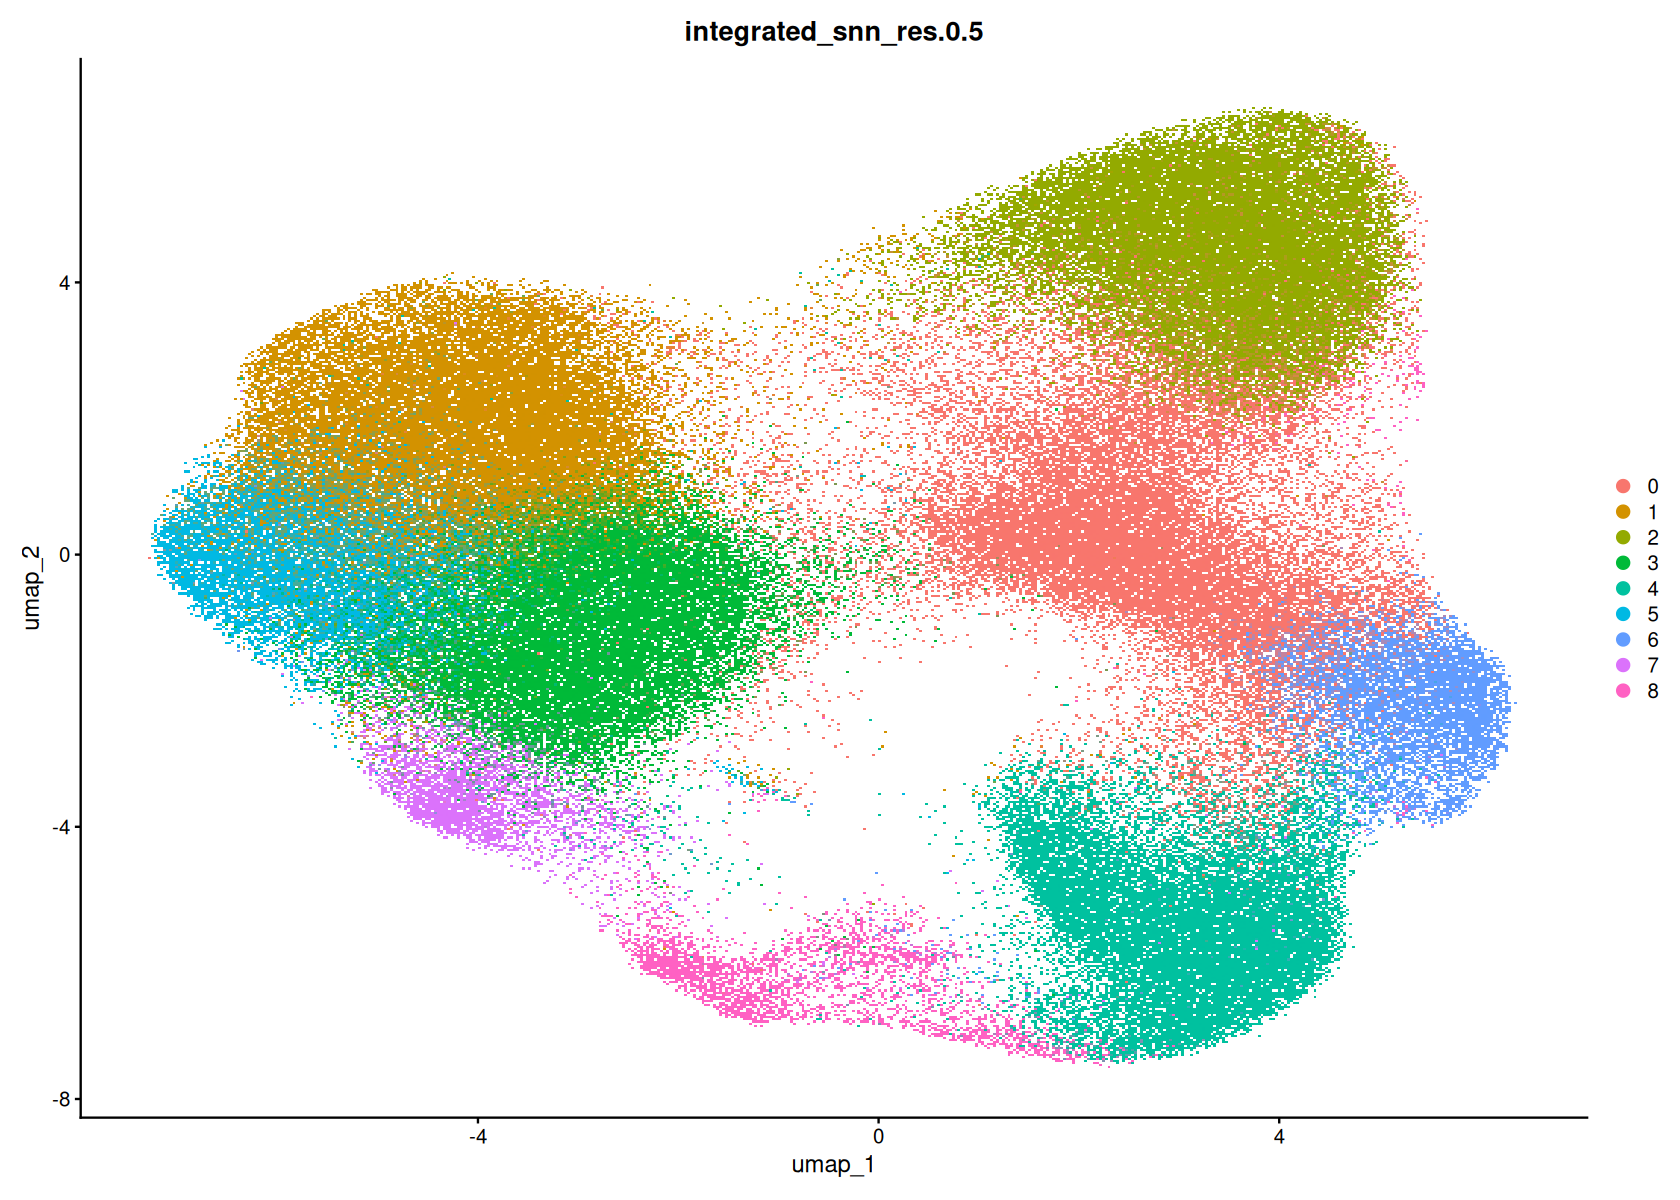

In [107]:
DimPlot(cd4_3p_int, group.by = "integrated_snn_res.0.5")

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



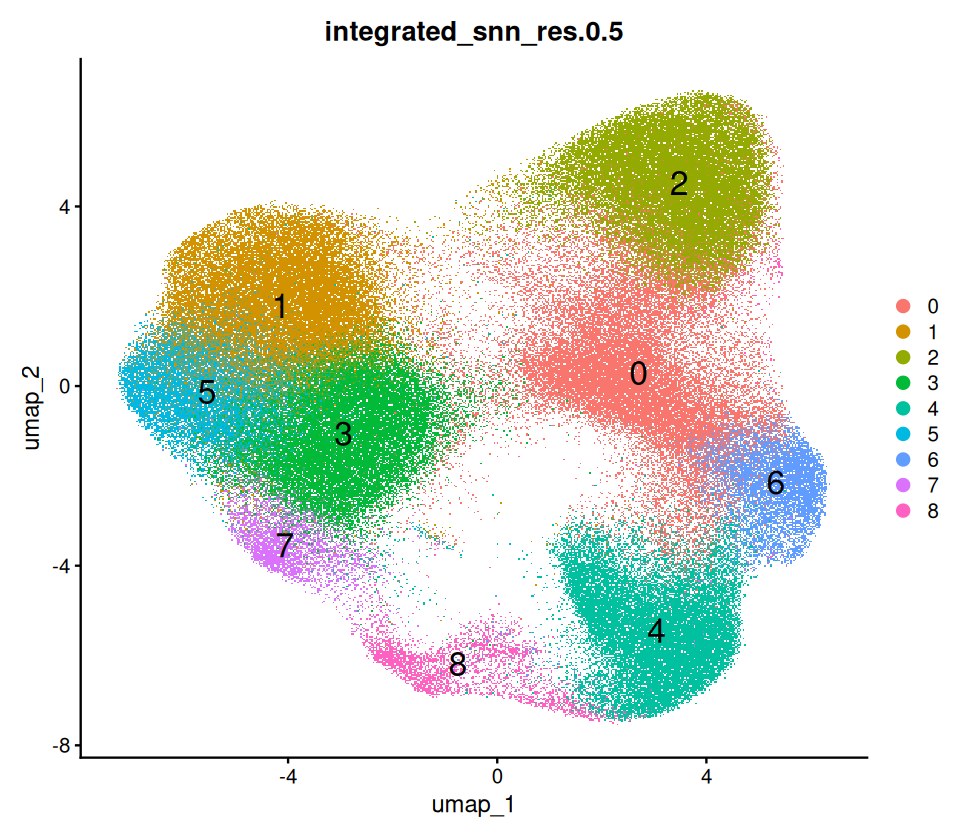

In [108]:
options(repr.plot.width = 8, repr.plot.height = 7)
DimPlot(cd4_3p_int, group.by = "integrated_snn_res.0.5", label = T, label.size = 7)

In [199]:
ls()

[1] "all_annotations"    "avgexp"             "cd4_3p"            
 [4] "cd4_3p_int"         "cd4_3p_int_save"    "cd4_v3"            
 [7] "cluster_labels"     "cluster_levels"     "df_counts"         
[10] "df_counts_complete" "df_filt"            "df_freq"           
[13] "df_tiss"            "df4"                "diagnosis_colors"  
[16] "genes.blocklist"    "ggtheme"            "gut_3p_integrated" 
[19] "gut_allt_3p"        "markers1"           "markers2"          
[22] "markers3"           "md"                 "md_3p"             
[25] "md_filt"            "md_to_join"         "merged_ds"         
[28] "merged.list"        "mtx_ordered"        "mtx_ordered2"      
[31] "p_diag"             "p_resp"             "pallete"           
[34] "plot_cluster_freq"  "pt_df"              "response_colors"   
[37] "stat_test"          "tiss"

In [207]:
cluster_colors <- c(
  "1" = "#F28E2B",
  "2" = "#D4AA00",
  "3" = "#00BA38",
  "4" = "#00C896",
  "5" = "#8494FF",
  "6" = "#C99AC9",
  "7" = "#00B9F2",
  "8" = "#FF7899",
  "9" = "#E67BFA"
)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



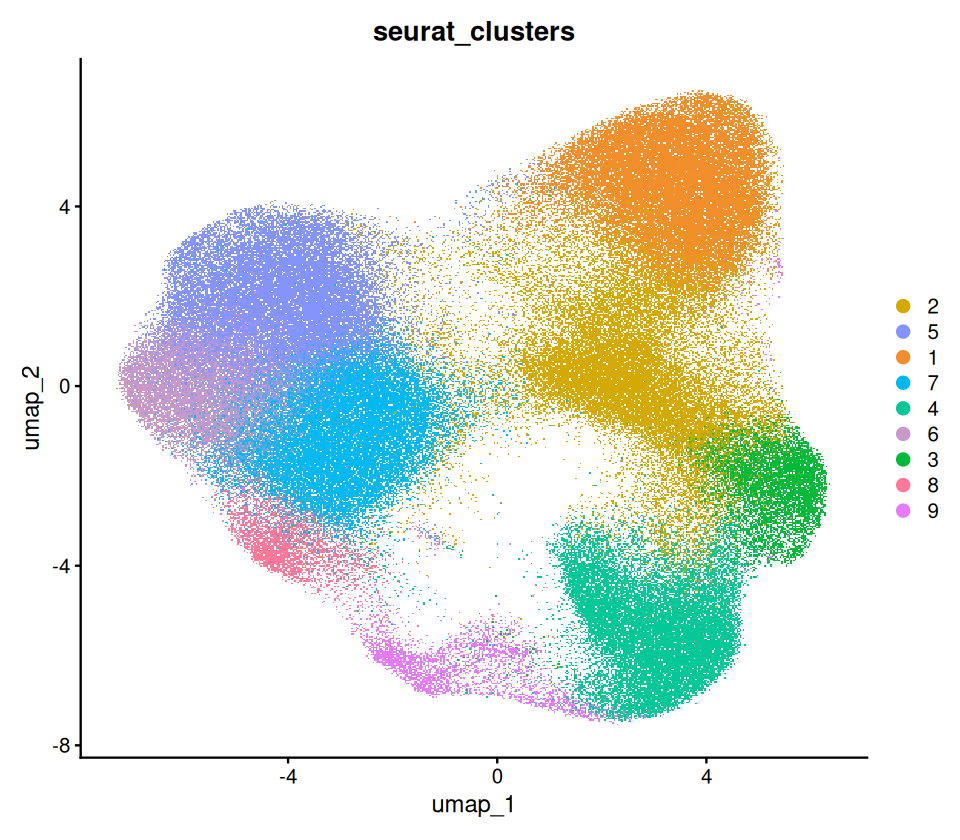

In [209]:
options(repr.plot.width = 8, repr.plot.height = 7)
DimPlot(cd4_3p_int, group.by = "seurat_clusters", cols = cluster_colors)

In [211]:
cd4_3p_int$cd4_ctl  <- cd4_3p_int$seurat_clusters == 8

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



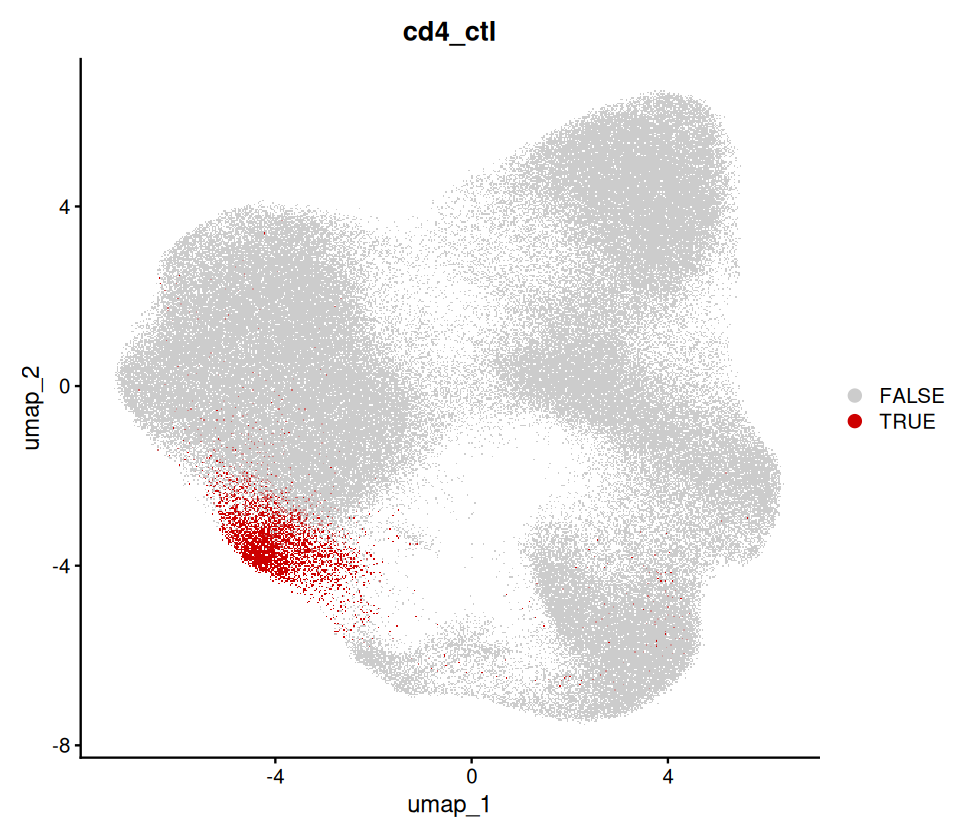

In [213]:
options(repr.plot.width = 8, repr.plot.height = 7)
DimPlot(cd4_3p_int, group.by = "cd4_ctl", cols = c("TRUE" = "red3", "FALSE" = "grey80"))

In [227]:
cd4_3p_int$cd4_ctl  %>% table

.
 FALSE   TRUE 
171030   4436 

In [ ]:
DimPlot(cd4_3p_int, group.by = "seurat_clusters", cols = cluster_colors)

Warning message:
“Could not find CD8A in the default search locations, found in ‘RNA’ assay instead”
Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



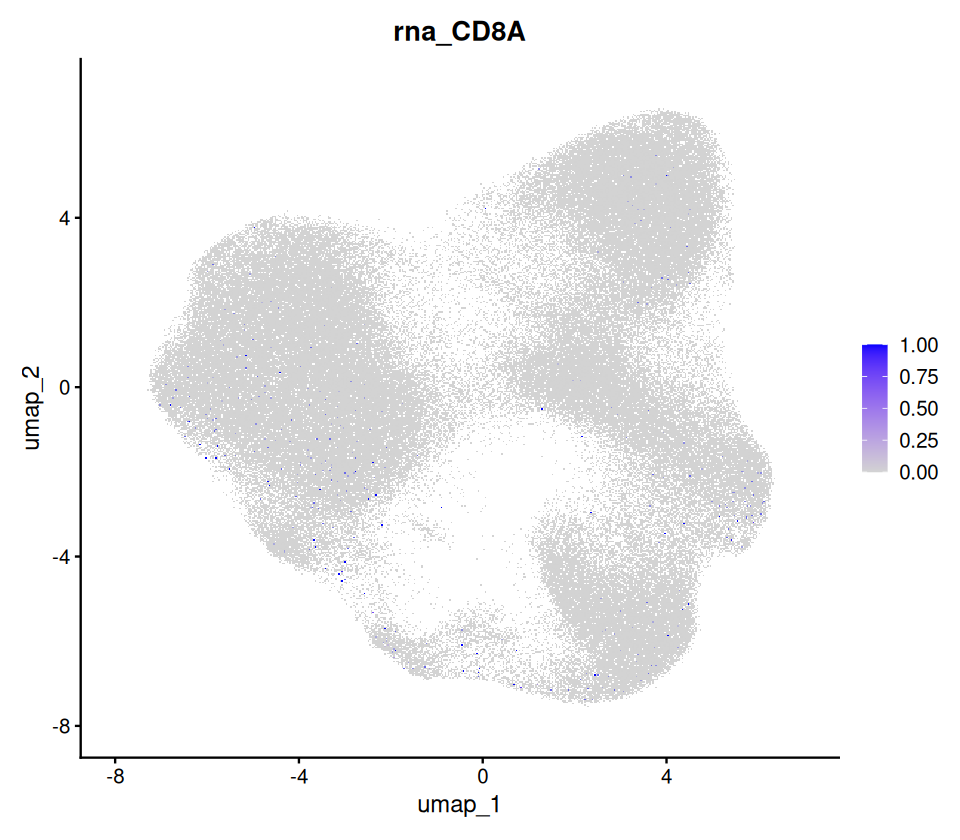

In [56]:
FeaturePlot(cd4_3p_int, features = "CD8A", max.cutoff = 1)

Warning message:
“Could not find CD8B in the default search locations, found in ‘RNA’ assay instead”
Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



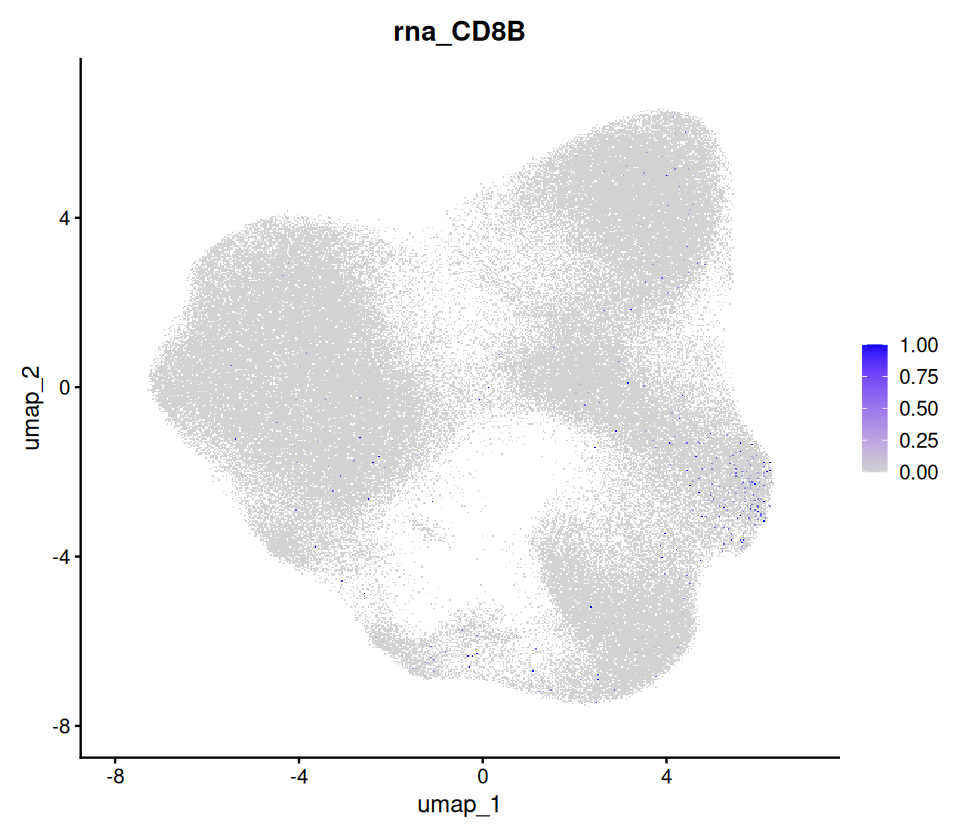

In [55]:
FeaturePlot(cd4_3p_int, features = "CD8B", max.cutoff = 1)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



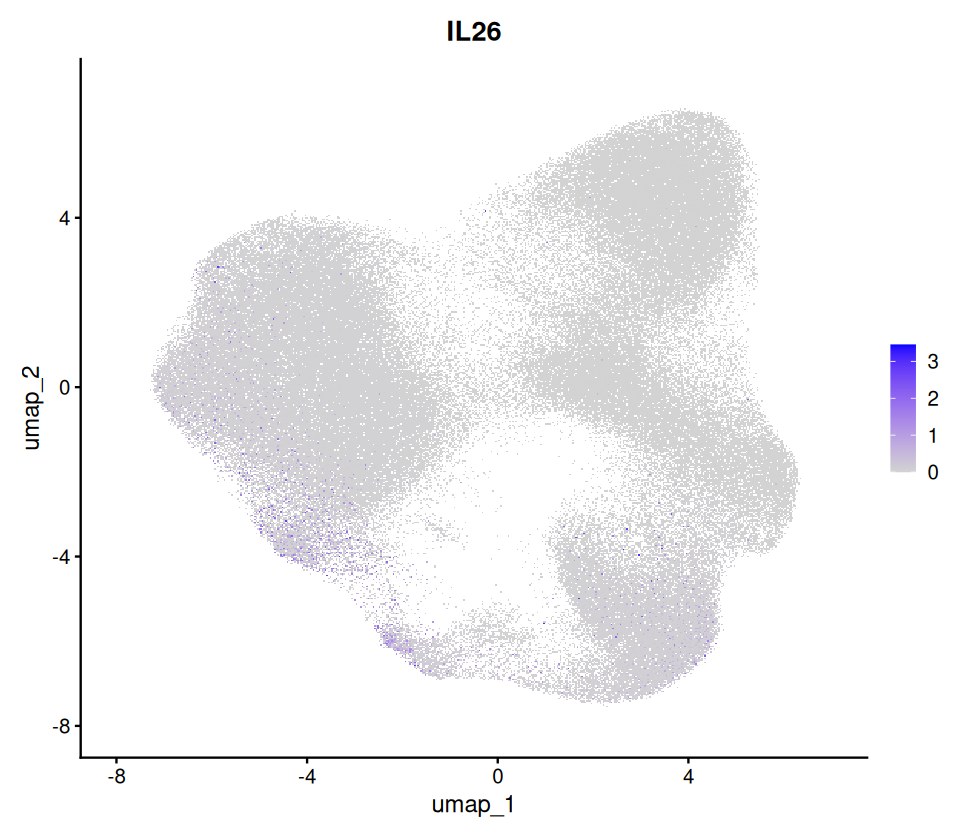

In [58]:
FeaturePlot(cd4_3p_int, features = "IL26", min.cutoff = 0)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



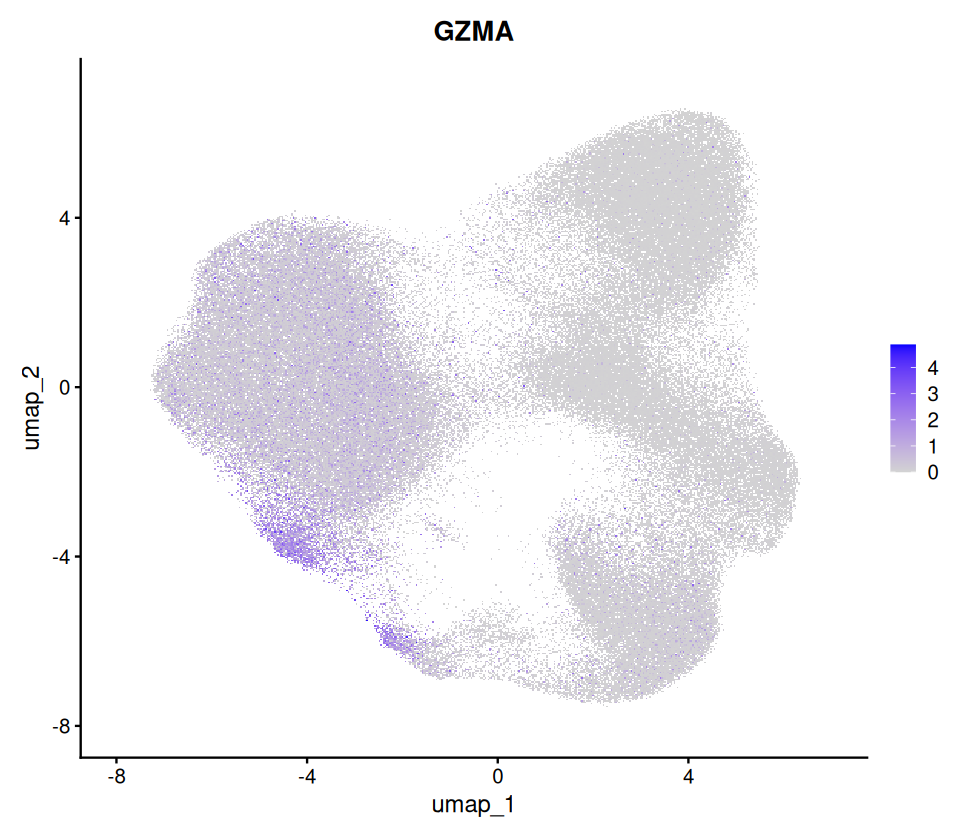

In [59]:
FeaturePlot(cd4_3p_int, features = "GZMA", min.cutoff = 0)

In [109]:
cd4_3p_int$seurat_clusters  <- cd4_3p_int$`integrated_snn_res.0.5`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



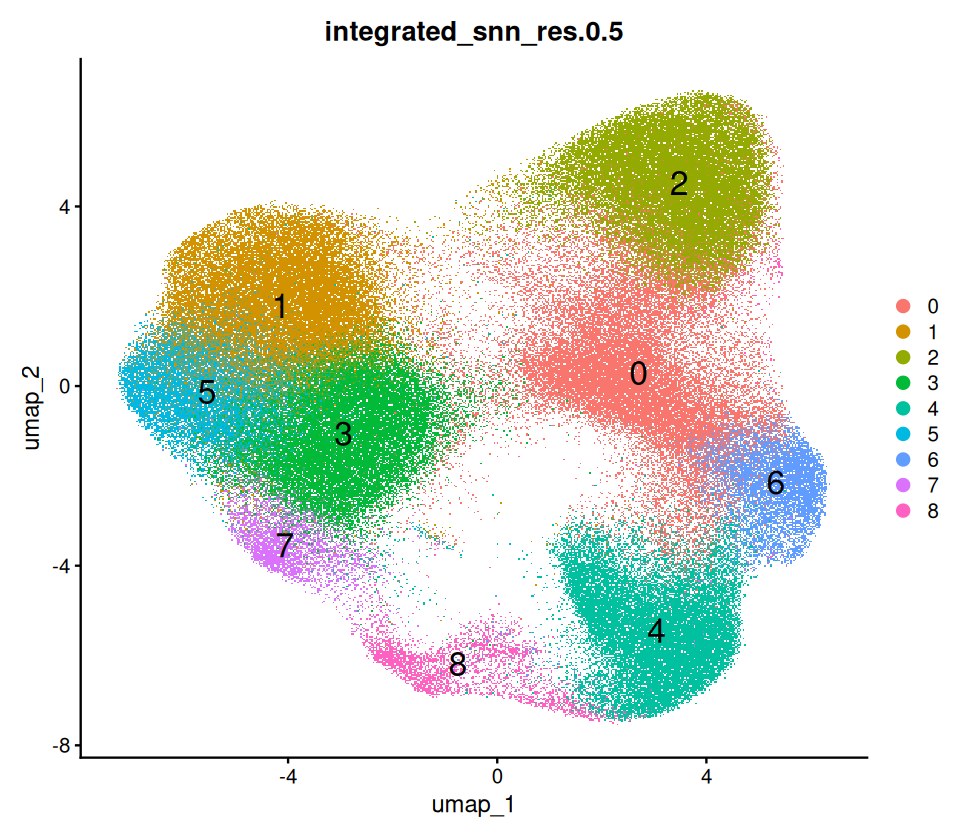

In [110]:
options(repr.plot.width = 8, repr.plot.height = 7)
DimPlot(cd4_3p_int, group.by = "integrated_snn_res.0.5", label = T, label.size = 7)

In [ ]:
0 = Tcm
1 = Mixed Teff1
2 = Naive
3 = Th17
4 = Treg
5 = Mixed Teff2
6 = Tfh
7 = CD4 CTL
8 = Proliferating

In [113]:
    cd4_3p_int@meta.data  <-     cd4_3p_int@meta.data   %>% mutate(annotations2 =
                                                                   recode_factor(seurat_clusters, 
                                                                                "0" = "Tcm",
  "1" = "Mixed Teff1",
  "2" = "Naive",
  "3" = "Th17",
  "4" = "Treg",
  "5" = "Mixed Teff2",
  "6" = "Tfh",
  "7" = "CD4 CTL",
  "8" = "Proliferating")
)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



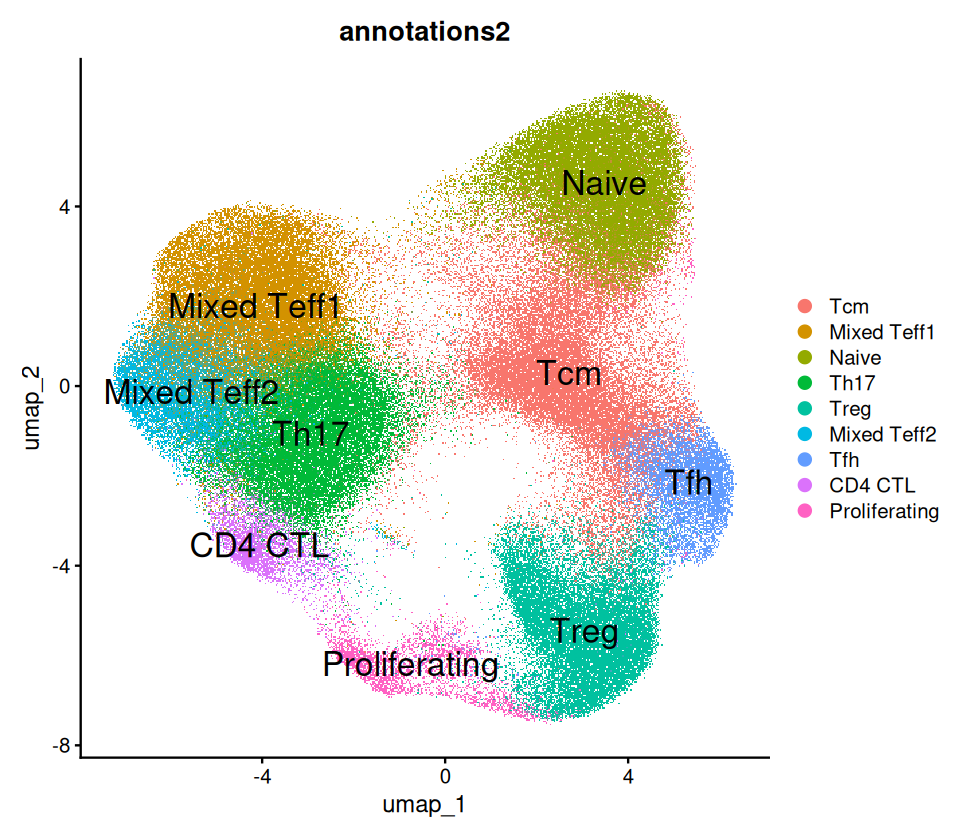

In [114]:
options(repr.plot.width = 8, repr.plot.height = 7)
DimPlot(cd4_3p_int, group.by = "annotations2", label = T, label.size = 7)

In [115]:
write.csv(cd4_3p_int@meta.data, "tables/261103_md_cd4_3p.csv")

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



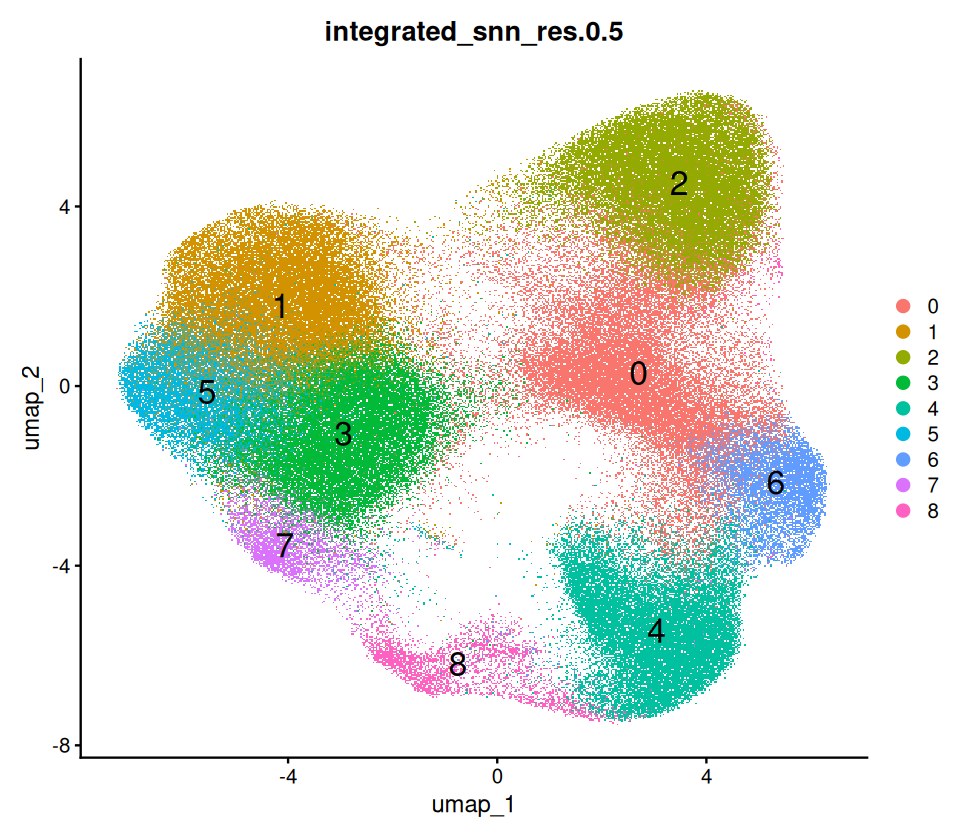

In [129]:
DimPlot(cd4_3p_int, group.by = "integrated_snn_res.0.5", label = T, label.size = 7)

In [132]:
    cd4_3p_int@meta.data  <-     cd4_3p_int@meta.data   %>% mutate(seurat_clusters_orig = seurat_clusters, 
                                                                   seurat_clusters =
                                                                   recode_factor(integrated_snn_res.0.5, 
                                                                                "0" = "2",
  "1" = "5",
  "2" = "1",
  "3" = "7",
  "4" = "4",
  "5" = "6",
  "6" = "3",
  "7" = "8",
  "8" = "9")
)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



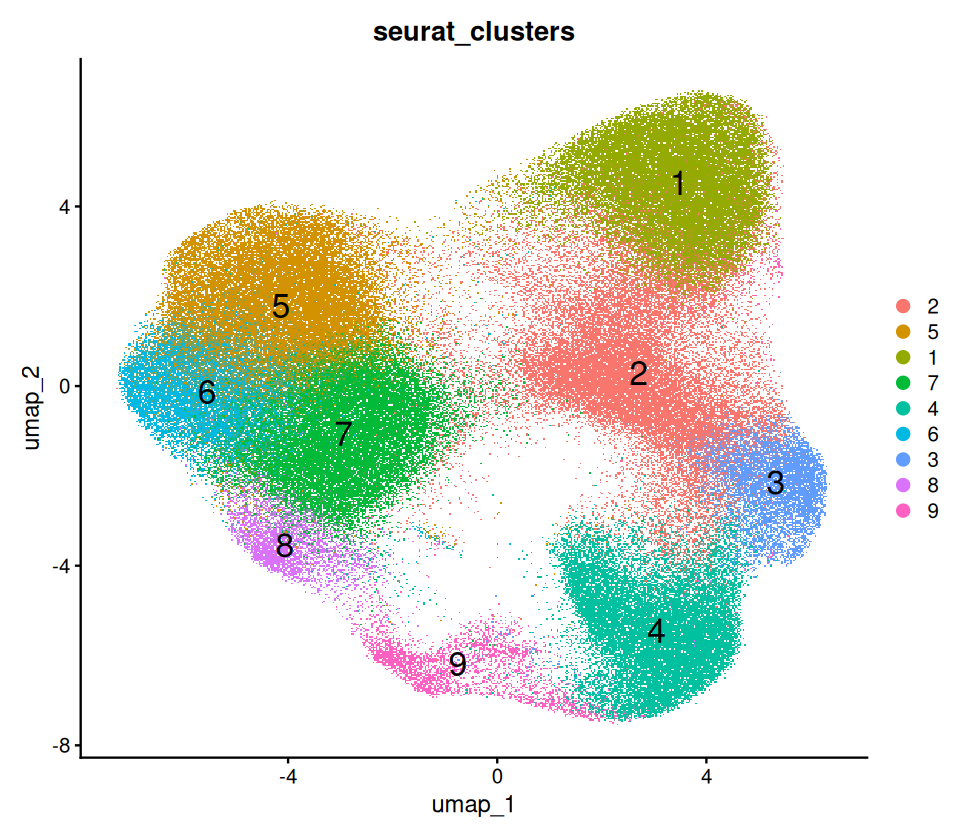

In [133]:
DimPlot(cd4_3p_int, group.by = "seurat_clusters", label = T, label.size = 7)

In [167]:
cd4_3p_int$annotations2  %>% table

.
          Tcm   Mixed Teff1         Naive          Th17          Treg 
        33199         31438         30966         27297         23274 
  Mixed Teff2           Tfh       CD4 CTL Proliferating 
        13007          8046          4436          3803 

In [216]:
cd4_3p_int_save  <- cd4_3p_int

In [217]:
cd4_3p_int_save@meta.data  <- cd4_3p_int_save@meta.data  %>% dplyr::select(orig.ident = smp_id, nCount_RNA, nFeature_RNA, 
                                                             seurat_clusters,
                                                             participant_id = patient, diagnosis = disease, 
                                                                           timepoint = time, 
                                                             tissue, layer, antitnf_response = antiTNF_response, annotations = annotations2)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



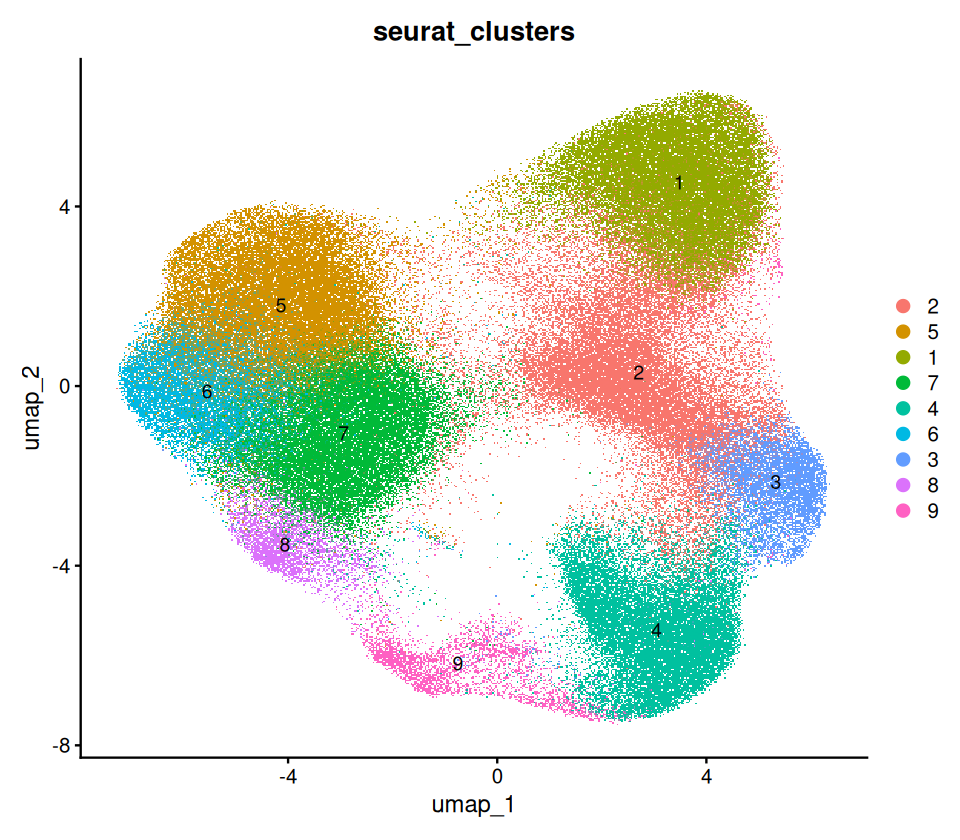

In [218]:
DimPlot(cd4_3p_int_save, label = T, group.by = "seurat_clusters")

In [173]:
saveRDS(cd4_3p_int_save, "..//251029_VN_PREDICT3/data/SCP/Gut_CD4_3p_updated.rds")

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



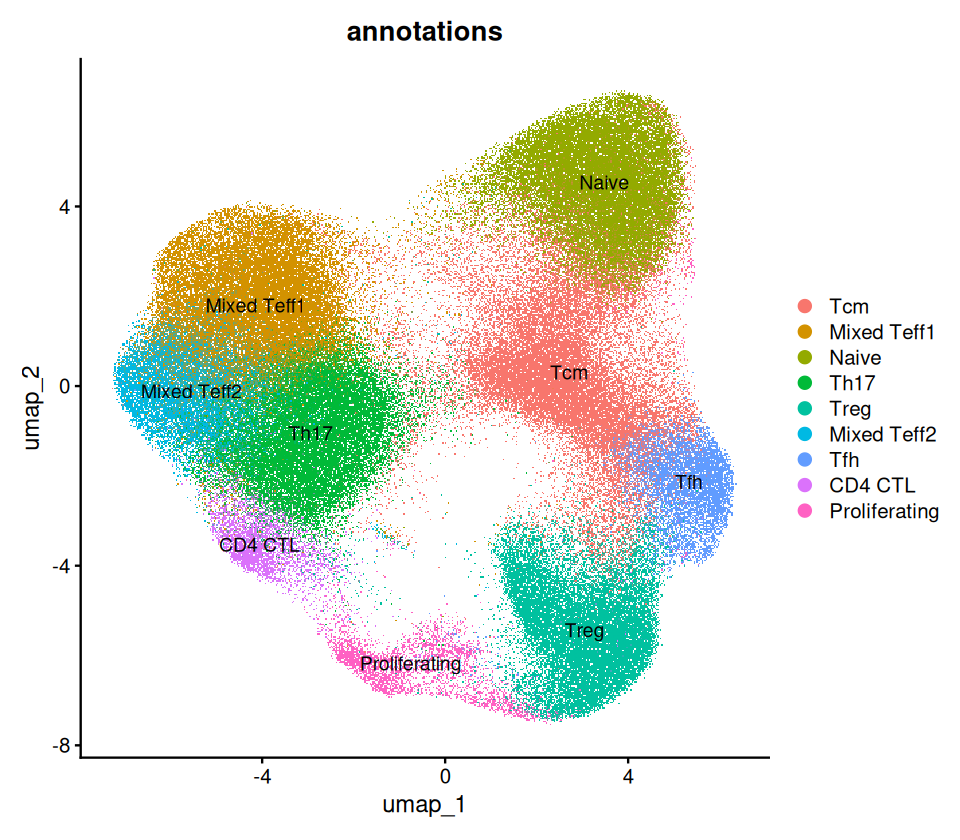

In [219]:
DimPlot(cd4_3p_int_save, label = T, group.by = "annotations")

In [179]:
cd4_3p_int_save@assays

$RNA
Assay data with 27494 features for 175466 cells
First 10 features:
 RP11-34P13.7, FO538757.2, AP006222.2, RP4-669L17.10, RP5-857K21.4,
RP11-206L10.9, LINC00115, FAM41C, SAMD11, NOC2L 

$integrated
Assay data with 1000 features for 175466 cells
Top 10 variable features:
 IGKC, STMN1, IL17A, CCL4, CXCL13, HIST1H4C, CCL20, IFNG, GNLY, TUBA1B 


### Export h5ad

In [184]:
cd4_3p_int_save@reductions$umap@cell.embeddings  

,umap_1,umap_2
Cell516_2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,5.9334969,-1.6391820
Cell6091_2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,4.5664634,0.0200009
Cell7487_2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,-2.4918433,-1.3892485
Cell1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,-5.0570384,0.8492943
Cell4_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,2.9865529,4.3553854
Cell9_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,-0.1782382,2.6410311
Cell16_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,1.3697446,0.9129263
Cell17_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,3.9162492,1.1358431
Cell18_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,1.8614021,0.7740671
Cell26_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,4.2172074,-1.6622154


In [220]:
cd4_3p_int_save$x_umap  <- cd4_3p_int_save@reductions$umap@cell.embeddings[,1]  

In [221]:
cd4_3p_int_save$y_umap  <- cd4_3p_int_save@reductions$umap@cell.embeddings[,2]  

In [222]:
cd4_3p_int_save@meta.data

,orig.ident,nCount_RNA,nFeature_RNA,seurat_clusters,participant_id,diagnosis,timepoint,tissue,layer,antitnf_response,annotations,x_umap,y_umap
,<chr>,<dbl>,<int>,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<fct>,<dbl>,<dbl>
Cell516_2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,NA,2290,995,3,p002,FGID,T0D,COL,EPI,NM,Tfh,5.9334969,-1.6391820
Cell6091_2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,NA,2117,899,2,p002,FGID,T0D,COL,EPI,NM,Tcm,4.5664634,0.0200009
Cell7487_2_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,NA,1703,762,7,p002,FGID,T0D,COL,EPI,NM,Th17,-2.4918433,-1.3892485
Cell1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,NA,1379,634,5,p002,FGID,T0D,COL,LP,NM,Mixed Teff1,-5.0570384,0.8492943
Cell4_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,NA,1331,572,1,p002,FGID,T0D,COL,LP,NM,Naive,2.9865529,4.3553854
Cell9_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,NA,703,361,2,p002,FGID,T0D,COL,LP,NM,Tcm,-0.1782382,2.6410311
Cell16_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,NA,1439,660,2,p002,FGID,T0D,COL,LP,NM,Tcm,1.3697446,0.9129263
Cell17_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,NA,1915,748,2,p002,FGID,T0D,COL,LP,NM,Tcm,3.9162492,1.1358431
Cell18_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1_1,NA,1079,499,2,p002,FGID,T0D,COL,LP,NM,Tcm,1.8614021,0.7740671


In [223]:
cd4_3p_int_save@meta.data  %>% colnames

[1] "orig.ident"       "nCount_RNA"       "nFeature_RNA"     "seurat_clusters" 
 [5] "participant_id"   "diagnosis"        "timepoint"        "tissue"          
 [9] "layer"            "antitnf_response" "annotations"      "x_umap"          
[13] "y_umap"

In [224]:
cd4_3p_int_save$annotations  %>% table

.
          Tcm   Mixed Teff1         Naive          Th17          Treg 
        33199         31438         30966         27297         23274 
  Mixed Teff2           Tfh       CD4 CTL Proliferating 
        13007          8046          4436          3803 

In [225]:
cd4_3p_int@meta.data  %>% colnames

[1] "SingleR_HPCA"           "nCount_RNA"             "nFeature_RNA"          
 [4] "RNA_snn_res.0.3"        "seurat_clusters"        "orig.ident"            
 [7] "smp_id"                 "percent.mt"             "patient"               
[10] "time"                   "tissue"                 "layer"                 
[13] "prime"                  "RNA_snn_res.0.2"        "RNA_snn_res.0.6"       
[16] "RNA_snn_res.0.7"        "RNA_snn_res.0.8"        "manual_annotation"     
[19] "smp_id2"                "disease"                "antiTNF_response"      
[22] "barcode"                "integrated_snn_res.0.3" "integrated_snn_res.0.5"
[25] "integrated_snn_res.0.7" "integrated_snn_res.0.9" "annotations_coarse"    
[28] "cd4"                    "cd8"                    "cd4_or_cd8"            
[31] "cd4_or_cd8_2"           "integrated_snn_res.1"   "integrated_snn_res.1.1"
[34] "integrated_snn_res.1.2" "data_folder"            "annotations2"          
[37] "seurat_clusters_orig"   "cd4_ctl"

In [226]:
library(SeuratDisk)

# Save Seurat object as h5Seurat
SaveH5Seurat(
  cd4_3p_int,
  filename = "cd4_3p_int_save.h5Seurat",
  overwrite = TRUE
)

# Convert to AnnData (.h5ad)
Convert(
  "cd4_3p_int_save.h5Seurat",
  dest = "h5ad",
  overwrite = TRUE
)

Creating h5Seurat file for version 3.1.5.9900

Adding counts for RNA

Adding data for RNA

No variable features found for RNA

No feature-level metadata found for RNA

Adding data for integrated

Adding scale.data for integrated

Adding variable features for integrated

No feature-level metadata found for integrated

Adding cell embeddings for pca

Adding loadings for pca

No projected loadings for pca

Adding standard deviations for pca

No JackStraw data for pca

Adding cell embeddings for umap

No loadings for umap

No projected loadings for umap

No standard deviations for umap

No JackStraw data for umap

Validating h5Seurat file

Adding scale.data from integrated as X

Adding data from integrated as raw

Transfering meta.data to obs

Adding dimensional reduction information for pca

Adding feature loadings for pca

Adding dimensional reduction information for umap

Adding integrated_snn as neighbors



In [125]:
library(dplyr)
library(tidyr)
library(tibble)

# Extract metadata
md <- cd4_3p_int@meta.data

# Get all annotations
all_annotations <- sort(unique(as.character(md$annotations2)))
all_annotations <- all_annotations[!is.na(all_annotations)]

# Prepare metadata
md_filt <- md %>%
  mutate(
    data_folder = as.character(data_folder),
    annotations2 = as.character(annotations2),
    participant_id = as.character(patient),

    # Recode timepoints
    timepoint = case_when(
      time %in% c("T0", "T0D") ~ "T0",
      time == "T3M" ~ "R",
      TRUE ~ NA_character_
    ),

    # Recode diagnoses
    diagnosis = case_when(
      disease %in% c("HEA", "Healthy") ~ "HEA",
      disease %in% c("FGID", "DGBI") ~ "FGID",
      disease == "CD" ~ "CD",
      disease == "UC" ~ "UC",
      TRUE ~ "OTH"
    ),

    # Recode anti-TNF response
    antitnf_response = case_when(
      antiTNF_response %in% c("NM", "NOA") ~ "NOA",
      antiTNF_response %in% c("RESP", "FR") ~ "FR",
      antiTNF_response == "PR" ~ "PR",
      TRUE ~ NA_character_
    )
  ) %>%
  filter(
    !is.na(data_folder),
    !is.na(annotations2),
    !is.na(timepoint)
  )

# Count cells per sample and annotation
df_counts <- md_filt %>%
  dplyr::count(
    data_folder,
    participant_id,
    diagnosis,
    antitnf_response,
    timepoint,
    tissue,
    layer,
    annotations2,
    name = "n_cells"
  )

# Add missing annotations with zero cells
df_counts_complete <- df_counts %>%
  group_by(
    data_folder,
    participant_id,
    diagnosis,
    antitnf_response,
    timepoint,
    tissue,
    layer
  ) %>%
  complete(
    annotations2 = all_annotations,
    fill = list(n_cells = 0)
  ) %>%
  ungroup()

# Calculate frequencies
df_freq <- df_counts_complete %>%
  group_by(data_folder) %>%
  mutate(
    freq = n_cells / sum(n_cells)
  ) %>%
  ungroup() %>%
  select(
    data_folder,
    annotations2,
    freq,
    diagnosis,
    antitnf_response,
    participant_id,
    timepoint,
    tissue,
    layer
  ) %>%
  mutate(
    diagnosis = factor(
      diagnosis,
      levels = c("HEA", "FGID", "UC", "CD", "OTH")
    ),
    antitnf_response = factor(
      antitnf_response,
      levels = c("NOA", "FR", "PR")
    ),
    timepoint = factor(
      timepoint,
      levels = c("T0", "R")
    )
  )

# Check resulting data
head(df_freq)

# Number of samples
n_distinct(df_freq$data_folder)

# Number of zero-frequency observations
sum(df_freq$freq == 0)

# Check number of annotations per sample
df_freq %>%
  dplyr::count(data_folder) %>%
  dplyr::count(n)

# Check frequencies sum to 1 per sample
df_freq %>%
  group_by(data_folder) %>%
  summarise(
    total_freq = sum(freq),
    .groups = "drop"
  ) %>%
  print(n = Inf)

data_folder,annotations2,freq,diagnosis,antitnf_response,participant_id,timepoint,tissue,layer
<chr>,<chr>,<dbl>,<fct>,<fct>,<chr>,<fct>,<chr>,<chr>
HE-001-014 COL EPI T0,CD4 CTL,0.23076923,HEA,NOA,HE-001-014,T0,COL,EPI
HE-001-014 COL EPI T0,Mixed Teff1,0.00000000,HEA,NOA,HE-001-014,T0,COL,EPI
HE-001-014 COL EPI T0,Mixed Teff2,0.00000000,HEA,NOA,HE-001-014,T0,COL,EPI
HE-001-014 COL EPI T0,Naive,0.15384615,HEA,NOA,HE-001-014,T0,COL,EPI
HE-001-014 COL EPI T0,Proliferating,0.46153846,HEA,NOA,HE-001-014,T0,COL,EPI
HE-001-014 COL EPI T0,Tcm,0.07692308,HEA,NOA,HE-001-014,T0,COL,EPI


[1] 177

[1] 286

Storing counts in `nn`, as `n` already present in input
ℹ Use `name = "new_name"` to pick a new name.


n,nn
<int>,<int>
9,177


# A tibble: 177 × 2
    data_folder           total_freq
    <chr>                      <dbl>
  1 HE-001-014 COL EPI T0          1
  2 HE-001-014 COL LP T0           1
  3 HE-001-014 DUO EPI T0          1
  4 HE-001-014 DUO LP T0           1
  5 HE-001-014 ILE EPI T0          1
  6 HE-001-014 ILE LP T0           1
  7 HE-001-023 COL EPI T0          1
  8 HE-001-023 COL LP T0           1
  9 HE-001-023 DUO EPI T0          1
 10 HE-001-023 DUO LP T0           1
 11 HE-001-023 ILE EPI T0          1
 12 HE-001-023 ILE LP T0           1
 13 HE-001-024 COL LP T0           1
 14 HE-001-024 DUO EPI T0          1
 15 HE-001-024 DUO LP T0           1
 16 HE-001-024 ILE EPI T0          1
 17 HE-001-025 COL LP T0           1
 18 HE-001-025 DUO EPI T0          1
 19 HE-001-025 DUO LP T0           1
 20 HE-001-025 ILE LP T0           1
 21 HE-001-026 COL EPI T0          1
 22 HE-001-026 COL LP T0           1
 23 HE-001-026 DUO LP T0           1
 24 HE-001-026 ILE LP T0           1
 25 p002 COL EPI T

In [126]:
write.csv(df_freq, "tables/261103_making_freq_table_gut_cd4_3p.csv")

In [62]:
cd4_3p_int$data_folder  <- paste(cd4_3p_int$patient, cd4_3p_int$tissue, 
                                cd4_3p_int$layer, cd4_3p_int$time)

In [128]:
ls()

[1] "all_annotations"    "cd4_3p"             "cd4_3p_int"        
 [4] "cd4_v3"             "cluster_labels"     "cluster_levels"    
 [7] "df_counts"          "df_counts_complete" "df_filt"           
[10] "df_freq"            "df_tiss"            "df4"               
[13] "diagnosis_colors"   "genes.blocklist"    "ggtheme"           
[16] "gut_3p_integrated"  "gut_allt_3p"        "md"                
[19] "md_3p"              "md_filt"            "md_to_join"        
[22] "merged_ds"          "merged.list"        "p_diag"            
[25] "p_resp"             "pallete"            "plot_cluster_freq" 
[28] "pt_df"              "response_colors"    "stat_test"         
[31] "tiss"

In [134]:
md <- cd4_3p_int@meta.data
df4 <- md %>% group_by(data_folder, seurat_clusters) %>% 
  summarise(n = n()) %>% 
  unique() %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
pivot_wider(names_from = seurat_clusters, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!data_folder, names_to = "seurat_clusters", values_to = "freq")

# As we've lost non-grouping variables, let's join them back
md_to_join <- md %>% dplyr::select(time, tissue, layer, data_folder, patient) %>% unique()
df4  <- left_join(df4, md_to_join, by = "data_folder")


`summarise()` has grouped output by 'data_folder'. You can override using the
`.groups` argument.


In [135]:
cd4_3p_int$patient  %>% table

.
HE-001-014 HE-001-023 HE-001-024 HE-001-025 HE-001-026       p002       p003 
      1526       1604        356        391       1911       2252       3243 
      p009       p010       p011       p014       p015       p016       p017 
      7685       4784       8041       3468       8505       2820       1813 
      p018       p019       p020       p021       p022       p023       p024 
      7613       9448       5429       6265       2295       4253       4593 
      p025       p026       p027       p028       p030       p031       p032 
      5022       4330       6406       3881       4191       2916       4836 
      p033       p034       p035       p036       p037       p038       p040 
      4207       3052       1955       5712       2779       2876       3143 
      p041       p042       p043       p044       p045       p047       p048 
      4752       5963       3587       2850       2511       2832       2759 
      p049       p050 
      3379       3232 

In [136]:
md_3p  <- cd4_3p_int@meta.data

In [137]:
pt_df  <- md_3p  %>% group_by(patient, disease, antiTNF_response)  %>% tally()  %>% dplyr::select(-n)

In [138]:
pt_df

patient,disease,antiTNF_response
<chr>,<chr>,<chr>
HE-001-014,HEA,NM
HE-001-023,HEA,NM
HE-001-024,HEA,NM
HE-001-025,HEA,NM
HE-001-026,HEA,NM
p002,FGID,NM
p003,FGID,NM
p009,FGID,NM
p010,CD,PR


In [139]:
df4

data_folder,seurat_clusters,freq,time,tissue,layer,patient
<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>
HE-001-014 COL EPI T0,2,0.07692308,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,1,0.15384615,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,4,0.07692308,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,8,0.23076923,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,9,0.46153846,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,5,0.00000000,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,7,0.00000000,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,3,0.00000000,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,6,0.00000000,T0,COL,EPI,HE-001-014


Joining with `by = join_by(patient)`


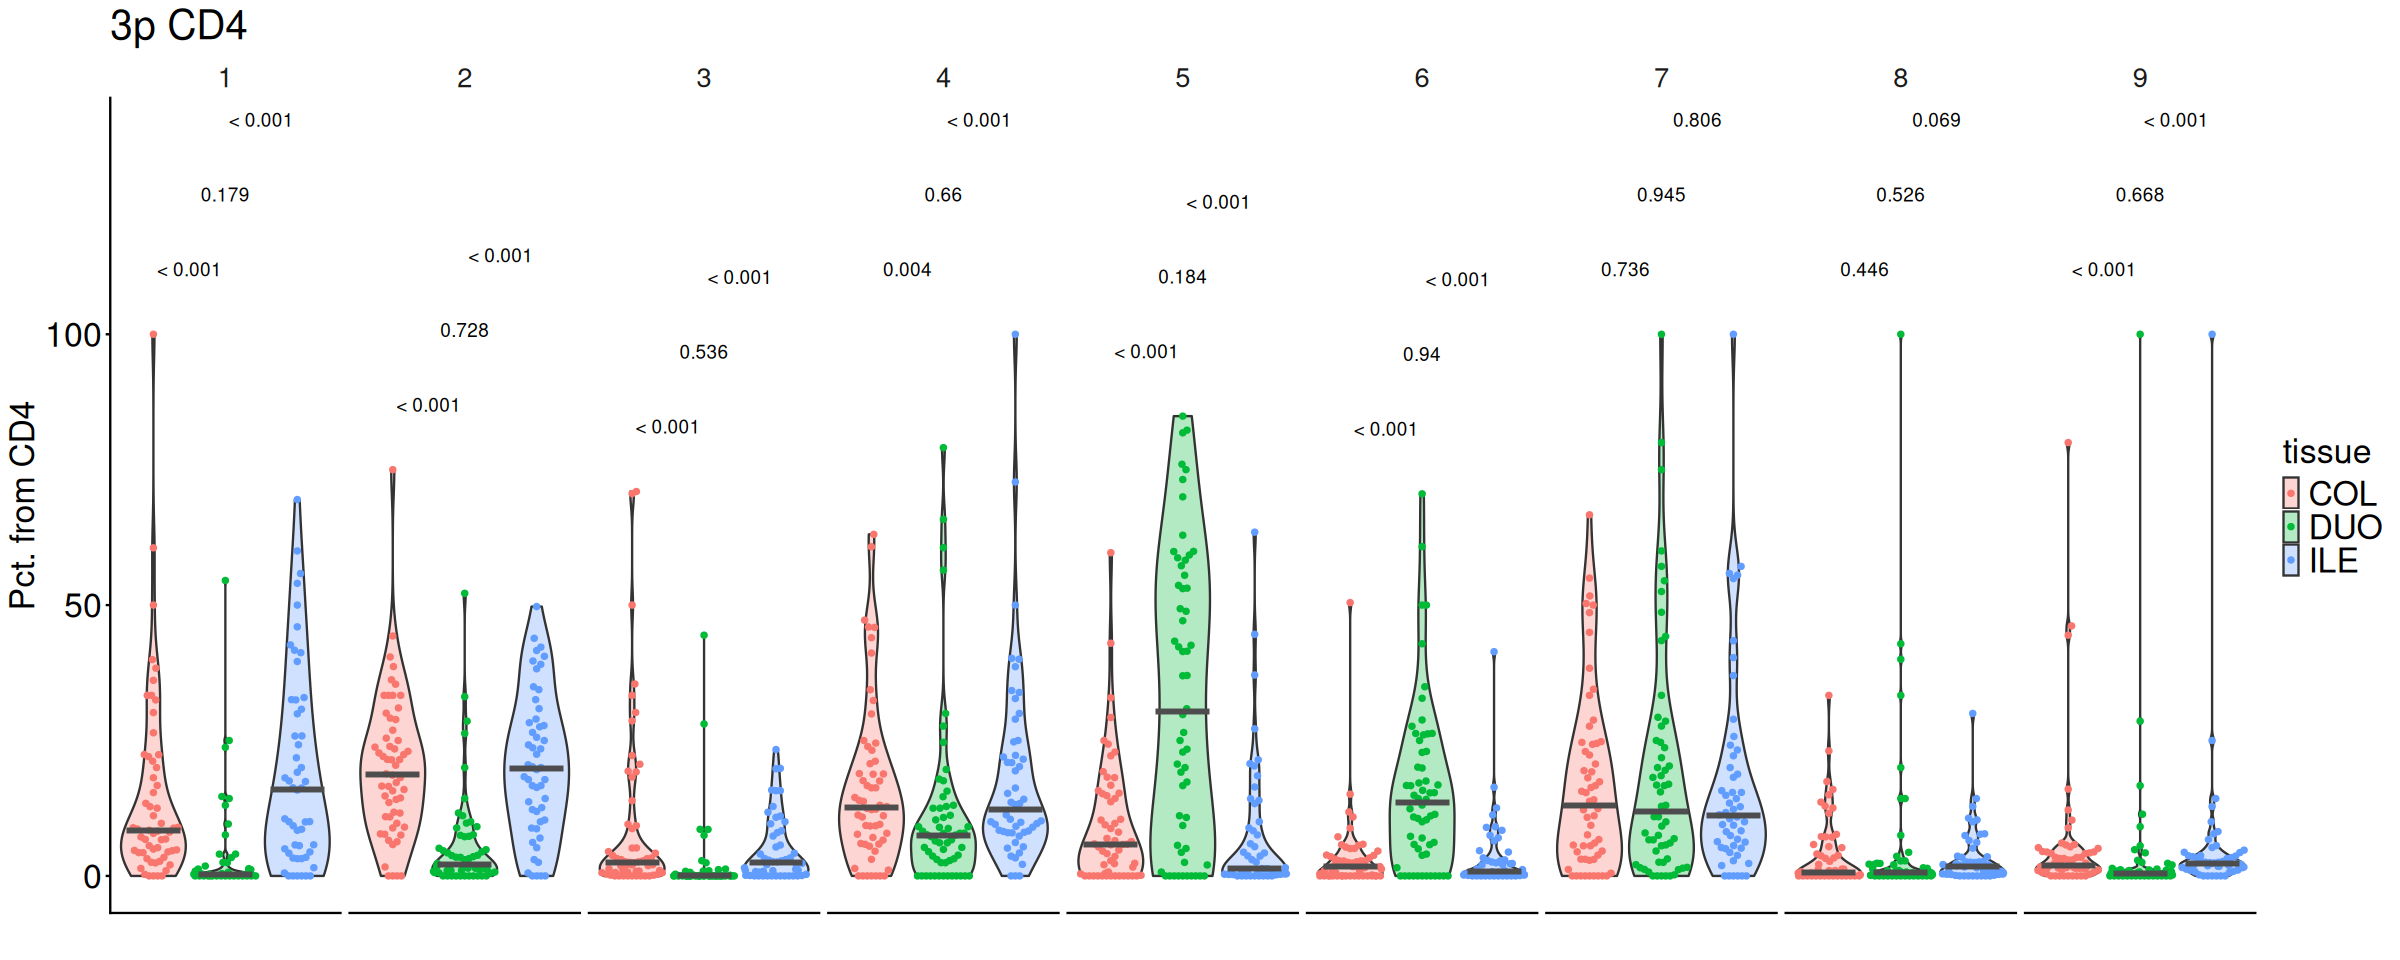

In [140]:
options(repr.plot.width = 20, repr.plot.height = 8)
df_filt <- df4 %>% 
left_join(pt_df)  %>% 
dplyr::filter(disease %in% c("UC","CD","FGID","HEA") )

stat_test <- df_filt %>%
mutate(freq100 = freq*100)  %>% 
  group_by(seurat_clusters) %>%
  rstatix::wilcox_test(freq100 ~ tissue) %>%
  mutate(p.label = ifelse(p < 0.001, "< 0.001", round(p, 3))) %>%
  rstatix::add_y_position() 

df_filt  %>% 
ggplot(aes(x = tissue, y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = tissue), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = tissue), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~seurat_clusters, ncol = 10) +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "3p CD4") +
#ggpubr::stat_compare_means(comparisons = list(c(1,2),c(1,3),c(1,4)), label = "p.signif") +
stat_pvalue_manual(
    stat_test, label = "p.label", 
    #y.position = 60,
    remove.bracket = TRUE
    ) + 
ggtheme()
 


Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_segment()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_segment()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_segment()`).”


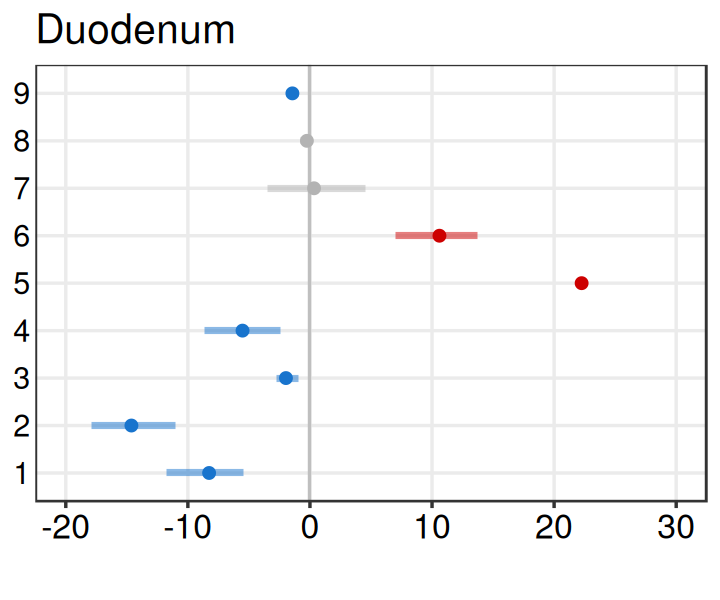

In [141]:
stat_test <- df_filt %>%
mutate(freq100 = freq*100)  %>%
mutate(duo = ifelse(tissue == "DUO","DUO","Other"))  %>% 
  group_by(seurat_clusters) %>%
  rstatix::wilcox_test(freq100 ~ duo, detailed = TRUE) 

options(repr.plot.width = 6, repr.plot.height = 5)
stat_test %>%
  mutate(upper = conf.high,
         lower = conf.low) %>%
  #mutate(across(all_of(c(
  #  "estimate", "lower", "upper"
  #)), exp)) %>%
  mutate(upper = ifelse(upper > 75, 74.9999, upper)) %>%
  mutate(lower = ifelse(lower < -25, -24.9999, lower)) %>%
  arrange(seurat_clusters) %>%
  ggplot(aes(estimate, seurat_clusters,
             color = ifelse(p*9>0.05,"1",ifelse(estimate > 1,"2","3")))) +
  geom_vline(xintercept = 0, color = "gray75") +
  geom_linerange(aes(xmin = lower, xmax = upper),
                 size = 1.5,
                 alpha = 0.5) +
  geom_point(size = 2.5) +
  theme_bw(base_size = 16) +
  scale_color_manual(values = c("3" = "dodgerblue3", "1" = "grey70","2" = "red3"), guide = "none") +
  xlim(c(-20, 30)) +
  labs(title = "Duodenum", y = NULL,
       x = "") +
  theme(axis.text.y = element_text(hjust = 0, size = 18),
        panel.grid.minor = element_blank(), 
        axis.ticks.y = element_blank(), 
                axis.text = element_text(color = "black")) + ggtheme()


ggsave("figures/freq_of_populations_in_tissues_3p/duodenum.png", width = 7, height = 11, units = "cm", create.dir = T)
ggsave("figures/freq_of_populations_in_tissues_3p/duodenum.svg", width = 7, height = 11, units = "cm", create.dir = T)

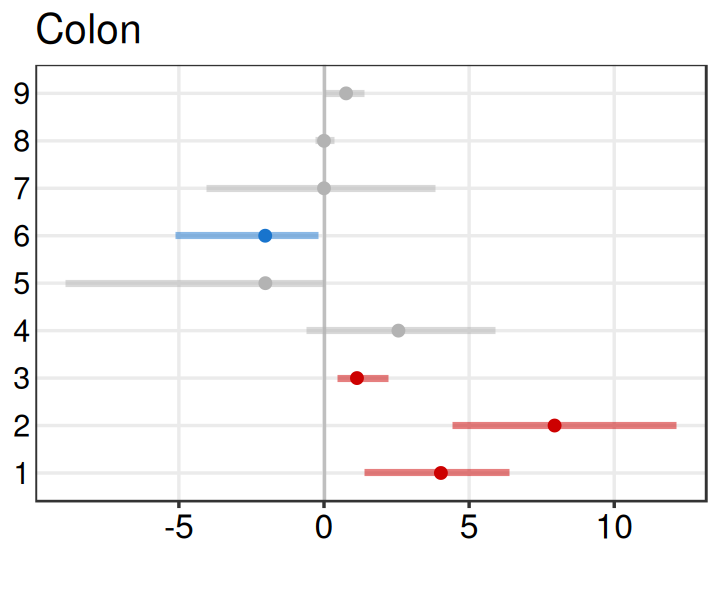

In [142]:
stat_test <- df_filt %>%
mutate(freq100 = freq*100)  %>%
mutate(col = ifelse(tissue == "COL","COL","Other"))  %>% 
  group_by(seurat_clusters) %>%
  rstatix::wilcox_test(freq100 ~ col, detailed = TRUE) 

stat_test %>%
  mutate(upper = conf.high,
         lower = conf.low) %>%
  #mutate(across(all_of(c(
  #  "estimate", "lower", "upper"
  #)), exp)) %>%
  mutate(upper = ifelse(upper > 75, 74.9999, upper)) %>%
  mutate(lower = ifelse(lower < -25, -24.9999, lower)) %>%
  arrange(seurat_clusters) %>%
  ggplot(aes(estimate, seurat_clusters,
             color = ifelse(p*9>0.05,"1",ifelse(estimate > 1,"2","3")))) +
  geom_vline(xintercept = 0, color = "gray75") +
  geom_linerange(aes(xmin = lower, xmax = upper),
                 size = 1.5,
                 alpha = 0.5) +
  geom_point(size = 2.5) +
  theme_bw(base_size = 16) +
  scale_color_manual(values = c("3" = "dodgerblue3", "1" = "grey70","2" = "red3"), guide = "none") +
  #xlim(c(-20, 30)) +
  labs(title = "Colon", y = NULL,
       x = "") +
  theme(axis.text.y = element_text(hjust = 0, size = 18),
        panel.grid.minor = element_blank(), 
        axis.ticks.y = element_blank(), 
                axis.text = element_text(color = "black")) + ggtheme()

ggsave("figures/freq_of_populations_in_tissues_3p/colon.png", width = 7, height = 11, units = "cm", create.dir = T)
ggsave("figures/freq_of_populations_in_tissues_3p/colon.svg", width = 7, height = 11, units = "cm", create.dir = T)

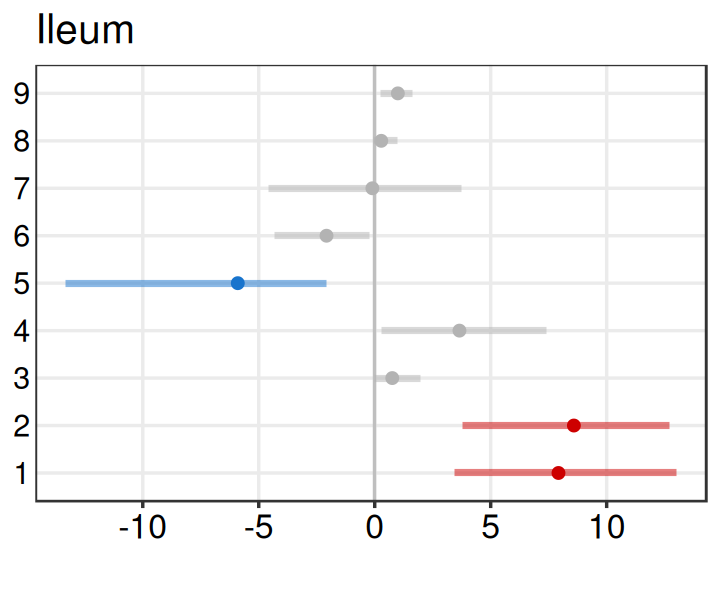

In [143]:
stat_test <- df_filt %>%
mutate(freq100 = freq*100)  %>%
mutate(ile = ifelse(tissue == "ILE","ILE","Other"))  %>% 
  group_by(seurat_clusters) %>%
  rstatix::wilcox_test(freq100 ~ ile, detailed = TRUE) 

stat_test %>%
  mutate(upper = conf.high,
         lower = conf.low) %>%
  #mutate(across(all_of(c(
  #  "estimate", "lower", "upper"
  #)), exp)) %>%
  mutate(upper = ifelse(upper > 75, 74.9999, upper)) %>%
  mutate(lower = ifelse(lower < -25, -24.9999, lower)) %>%
  arrange(seurat_clusters) %>%
  ggplot(aes(estimate, seurat_clusters,
             color = ifelse(p*9>0.05,"1",ifelse(estimate > 1,"2","3")))) +
  geom_vline(xintercept = 0, color = "gray75") +
  geom_linerange(aes(xmin = lower, xmax = upper),
                 size = 1.5,
                 alpha = 0.5) +
  geom_point(size = 2.5) +
  theme_bw(base_size = 16) +
  scale_color_manual(values = c("3" = "dodgerblue3", "1" = "grey70","2" = "red3"), guide = "none") +
  #xlim(c(-20, 30)) +
  labs(title = "Ileum", y = NULL,
       x = "") +
  theme(axis.text.y = element_text(hjust = 0, size = 18),
        panel.grid.minor = element_blank(), 
        axis.ticks.y = element_blank(), 
                axis.text = element_text(color = "black")) + ggtheme()

ggsave("figures/freq_of_populations_in_tissues_3p/ileum.png", width = 7, height = 11, units = "cm", create.dir = T)
ggsave("figures/freq_of_populations_in_tissues_3p/ileum.svg", width = 7, height = 11, units = "cm", create.dir = T)

In [144]:
df4

data_folder,seurat_clusters,freq,time,tissue,layer,patient
<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>
HE-001-014 COL EPI T0,2,0.07692308,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,1,0.15384615,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,4,0.07692308,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,8,0.23076923,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,9,0.46153846,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,5,0.00000000,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,7,0.00000000,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,3,0.00000000,T0,COL,EPI,HE-001-014
HE-001-014 COL EPI T0,6,0.00000000,T0,COL,EPI,HE-001-014


In [145]:
options(repr.plot.width = 20, repr.plot.height = 4)

stat_test <- df_filt %>%
mutate(freq100 = freq*100)  %>% 
  group_by(seurat_clusters) %>%
  rstatix::wilcox_test(freq100 ~ layer) %>%
  mutate(p.label = ifelse(p < 0.001, "< 0.001", round(p, 3))) %>%
  rstatix::add_y_position() 

In [146]:
df_filt

data_folder,seurat_clusters,freq,time,tissue,layer,patient,disease,antiTNF_response
<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
HE-001-014 COL EPI T0,2,0.07692308,T0,COL,EPI,HE-001-014,HEA,NM
HE-001-014 COL EPI T0,1,0.15384615,T0,COL,EPI,HE-001-014,HEA,NM
HE-001-014 COL EPI T0,4,0.07692308,T0,COL,EPI,HE-001-014,HEA,NM
HE-001-014 COL EPI T0,8,0.23076923,T0,COL,EPI,HE-001-014,HEA,NM
HE-001-014 COL EPI T0,9,0.46153846,T0,COL,EPI,HE-001-014,HEA,NM
HE-001-014 COL EPI T0,5,0.00000000,T0,COL,EPI,HE-001-014,HEA,NM
HE-001-014 COL EPI T0,7,0.00000000,T0,COL,EPI,HE-001-014,HEA,NM
HE-001-014 COL EPI T0,3,0.00000000,T0,COL,EPI,HE-001-014,HEA,NM
HE-001-014 COL EPI T0,6,0.00000000,T0,COL,EPI,HE-001-014,HEA,NM


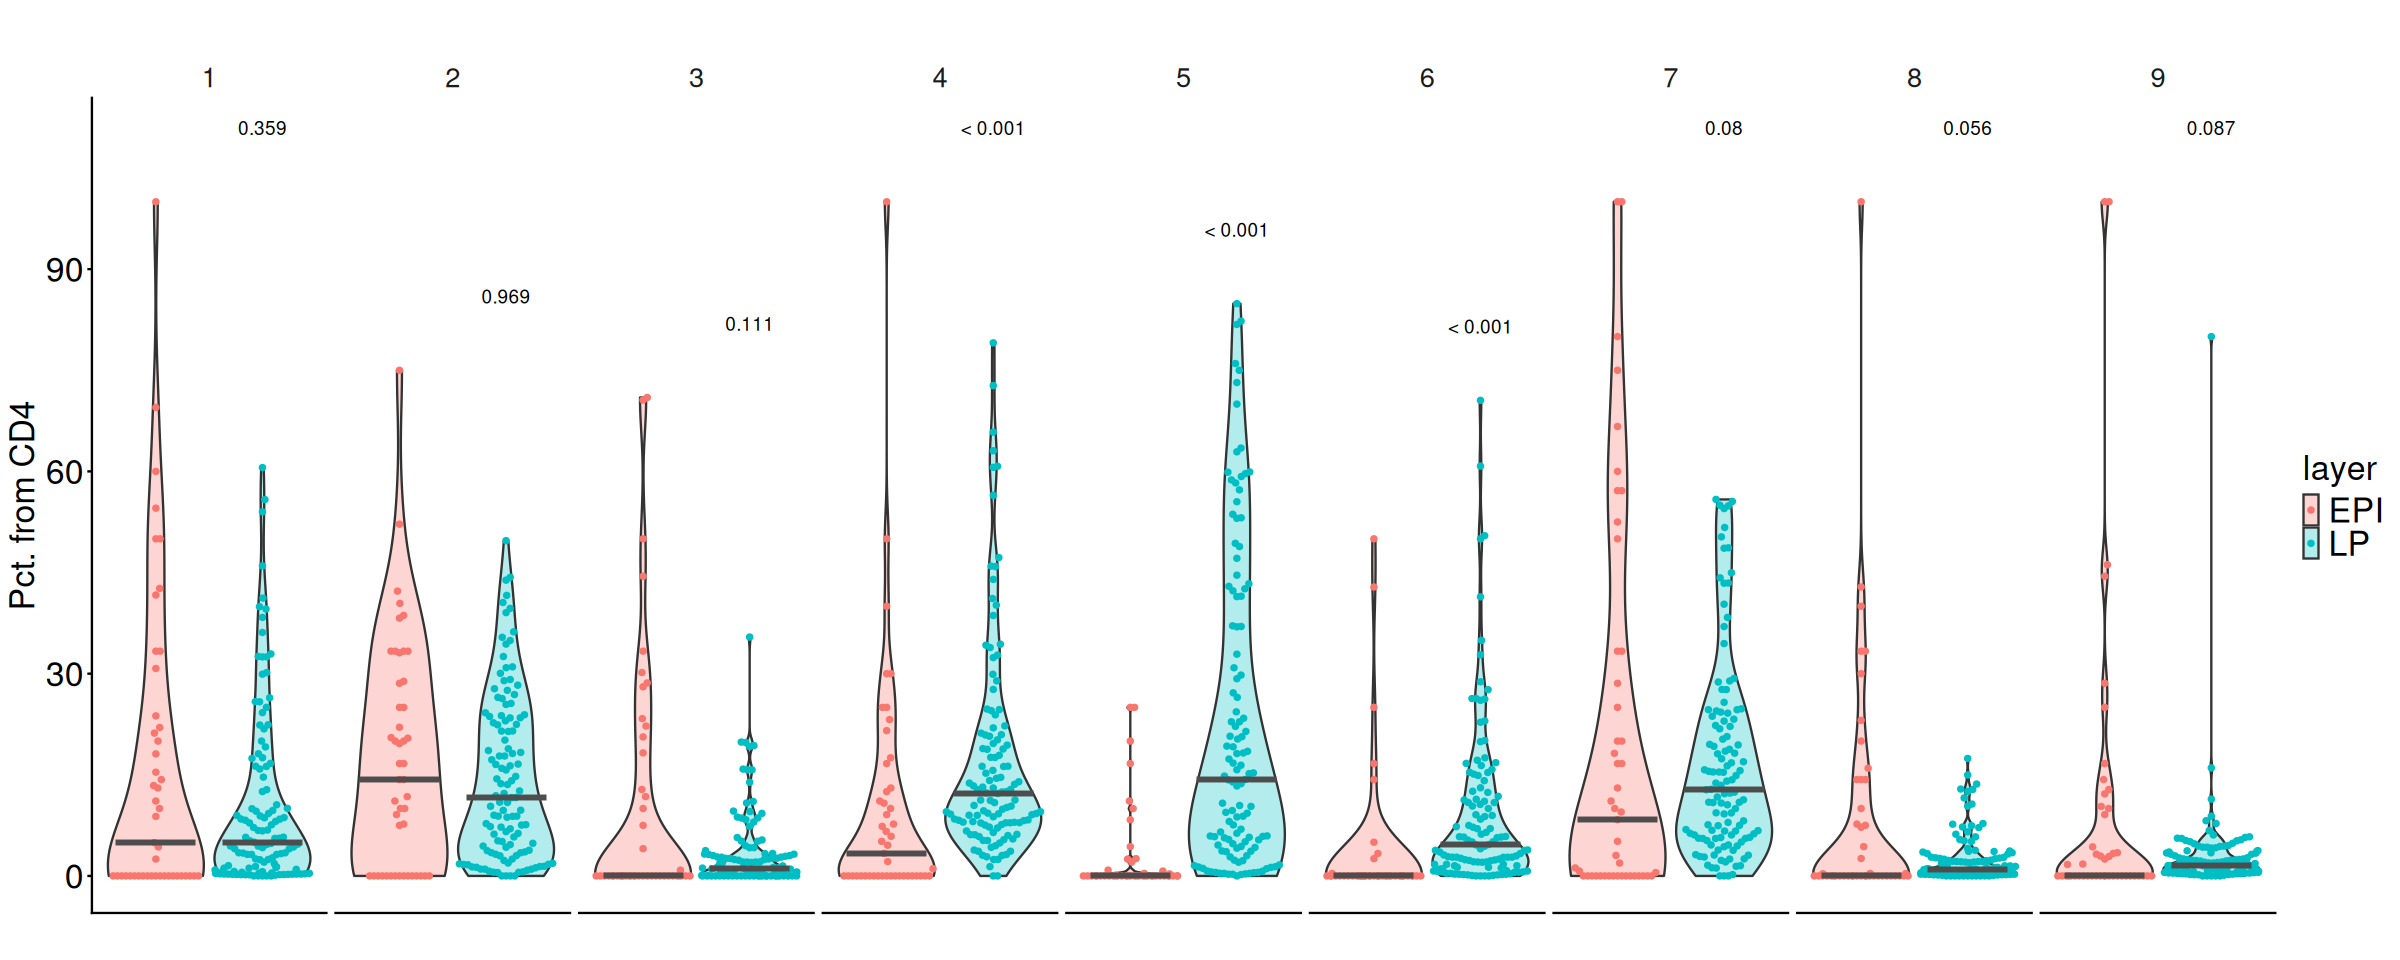

In [147]:
options(repr.plot.width = 20, repr.plot.height = 8)
df_filt  %>% 
ggplot(aes(x = layer, y = freq*100)) + # you can change the x to whatever variable you're interested in
geom_violin(alpha = 0.3, aes(fill = layer), scale = "width") + 
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = layer), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~seurat_clusters, ncol = 10) +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  #scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "") +
#ggpubr::stat_compare_means(comparisons = list(c(1,2),c(1,3),c(1,4)), label = "p.signif") +
stat_pvalue_manual(
    stat_test, label = "p.label", 
    #y.position = 60,
    remove.bracket = TRUE
    ) + 
ggtheme()
 
#ggsave("figures/boxplot_freq_gut_5p_24/241220_cdn_5p_layer.svg", width = 40, height = 9, units = "cm")
#ggsave("figures/boxplot_freq_gut_5p_24/241220_cdn_5p_layer.png", width = 40, height = 9, units = "cm")

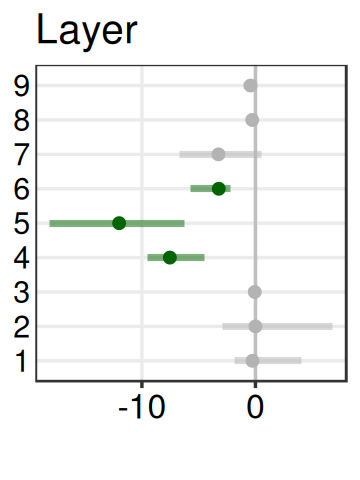

In [148]:
stat_test <- df_filt %>%
mutate(freq100 = freq*100)  %>% 
  group_by(seurat_clusters) %>%
  rstatix::wilcox_test(freq100 ~ layer, detailed = TRUE) 

options(repr.plot.width = 3, repr.plot.height = 4)

stat_test %>%
  mutate(upper = conf.high,
         lower = conf.low) %>%
  #mutate(across(all_of(c(
  #  "estimate", "lower", "upper"
  #)), exp)) %>%
  mutate(upper = ifelse(upper > 75, 74.9999, upper)) %>%
  mutate(lower = ifelse(lower < -25, -24.9999, lower)) %>%
  arrange(seurat_clusters) %>%
  ggplot(aes(estimate, seurat_clusters, 
             color = ifelse(p*9>0.05,"1",ifelse(estimate > 1,"2","3")))) +
  geom_vline(xintercept = 0, color = "gray75") +
  geom_linerange(aes(xmin = lower, xmax = upper),
                 size = 1.5,
                 alpha = 0.5) +
  geom_point(size = 2.5) +
  theme_bw(base_size = 16) +
  scale_color_manual(values = c("3" = "darkgreen", "1" = "grey70","2" = "orange3"), guide = "none") +
  #xlim(c(-20, 30)) +
  labs(title = "Layer", y = NULL,
       x = "") +
    theme(axis.text.y = element_text(hjust = 0, size = 18),
        panel.grid.minor = element_blank(), 
        axis.ticks.y = element_blank(), 
                axis.text = element_text(color = "black")) + ggtheme()

ggsave("figures/freq_of_populations_in_tissues_3p/layer.png", width = 9.5, height = 11, units = "cm", create.dir = T)
ggsave("figures/freq_of_populations_in_tissues_3p/layer.svg", width = 9.5, height = 11, units = "cm", create.dir = T)

# Marker heatmap

In [191]:
markers2 <- c(
  "LEF1", "CCR7", "SELL", "TCF7", "IL21",
  "CXCL13", "CXCR5", "IL4", "TNFRSF18", "IL2RA",
  "CTLA4", "IKZF2", "FOXP3", "KLRB1", "GATA3",
  "CCL5", "CD40LG", "GPR183", "GNLY", "GZMB",
  "IL17F", "HLA-DRA", "IFNG", "IL26", "PRF1",
  "IL22", "CXCR3", "CXCR6", "IL5", "IL23R",
  "RORC", "RORA", "CCR6", "TNF", "IL17A",
  "TBX21", "IL13", "S100A6", "KLRD1", "CD160",
  "XCL1"
)

In [193]:

avgexp = AverageExpression(cd4_3p_int, features = markers2, group.by = "seurat_clusters",
                          assay = "RNA")

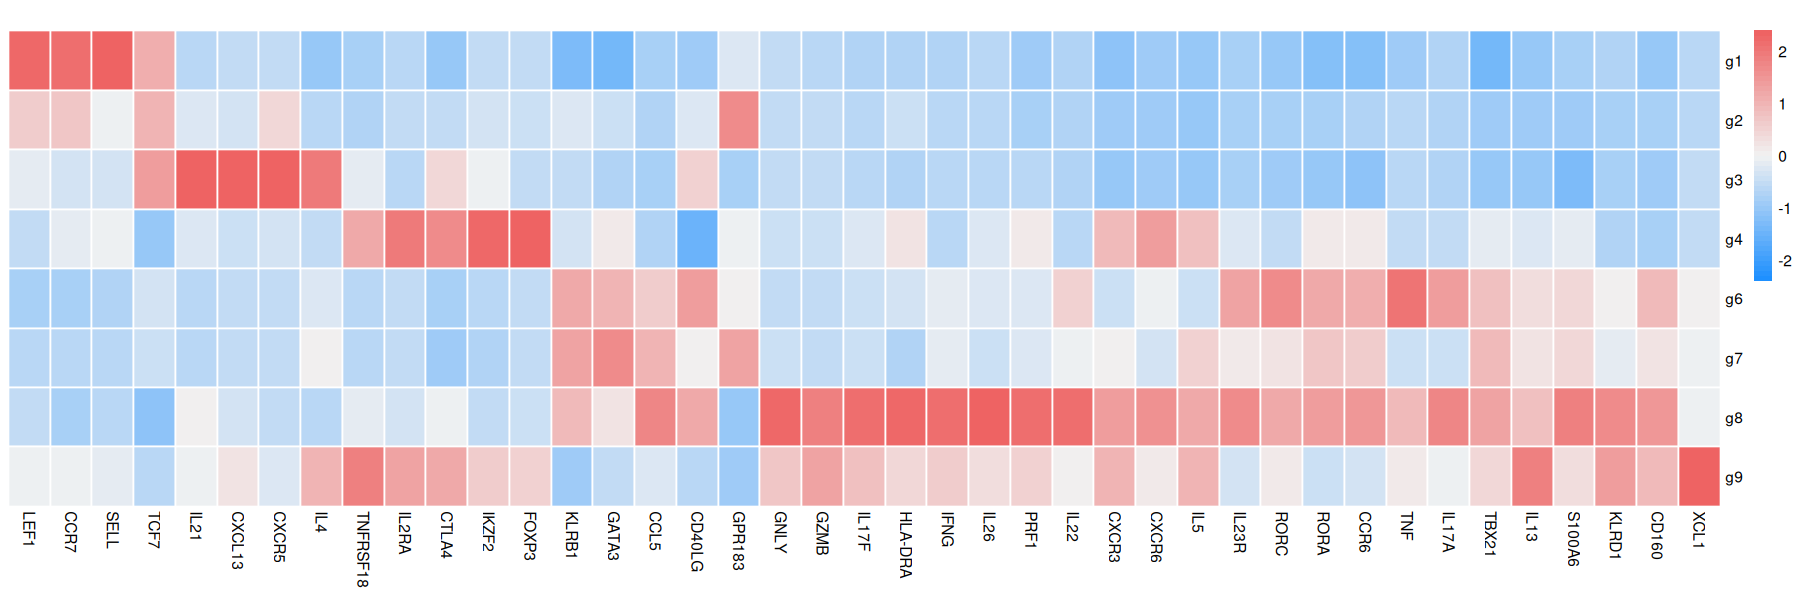

In [197]:
options(repr.plot.width = 15, repr.plot.height = 5)
pheatmap::pheatmap(t(avgexp$RNA)[c(3,1,7,5,6,4,8,9),], main = "", 
         scale = "column", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9)

In [112]:
dir.create("figures/characterization_CD4CTL/")

In [198]:
pheatmap::pheatmap(t(avgexp$RNA)[c(3,1,7,5,6,4,8,9),], main = "", 
         scale = "column", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9, filename = "figures/characterization_CD4CTL/heatmap_cluster_markers_3p.pdf",
                  width = 12, height = 4)

# CollecTRI 3p dataset

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



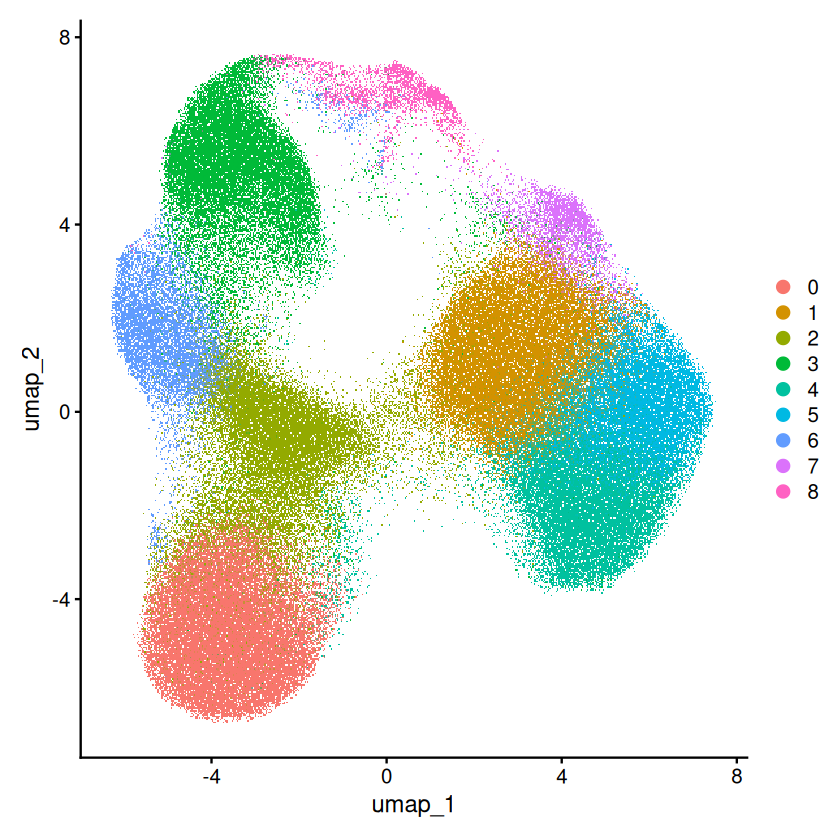

In [5]:
DimPlot(cd4)

net <- decoupleR::get_progeny(organism = 'human', top = 200)
net2 <- decoupleR::get_collectri(organism='human', split_complexes=FALSE)

options(future.globals.maxSize = 30000 * 1024^2)

 data <- cd4

In [6]:
# Extract the normalized log-transformed counts
mat <- as.matrix(data@assays$RNA$data)

Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 34.1 GiB”


In [7]:
# Extract the normalized log-transformed counts
mat <- as.matrix(data@assays$RNA$data)

######## Pathways Progeny #########   
    
# Run wmean
acts <- decoupleR::run_wmean(mat=mat, net=net, .source='source', .target='target',
                  .mor='weight', times = 100, minsize = 5)
  
# Add data to Seurat object

  data[['pathwayswmean']] <- acts %>%
  filter(statistic == 'norm_wmean') %>%
  pivot_wider(id_cols = 'source', names_from = 'condition',
              values_from = 'score') %>%
  column_to_rownames('source') %>%
  Seurat::CreateAssayObject(.)

  # Scale the data
DefaultAssay(object = data) <- "pathwayswmean"

Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 34.1 GiB”


In [8]:
######## CollecTRI ######### 

# Run ULM
acts <- decoupleR::run_ulm(mat=mat, net=net2, .source='source', .target='target',
                .mor='mor', minsize = 5)
  
# Add data to Seurat object
  data[['CollecTRI']] <- acts %>%
  pivot_wider(id_cols = 'source', names_from = 'condition',
              values_from = 'score') %>%
  column_to_rownames('source') %>%
  Seurat::CreateAssayObject(.)

  # Scale the data
DefaultAssay(object = data) <- "CollecTRI"

In [9]:
DefaultAssay(data)  <- "CollecTRI"

In [10]:
Idents(data)  <- data$seurat_clusters

In [11]:
coll  <- FindAllMarkers(data, only.pos = T)

Calculating cluster 0

Warning message:
“The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”
Warning message in mean.fxn(object[features, cells.1, drop = FALSE]):
“NaNs produced”
Warning message in mean.fxn(object[features, cells.2, drop = FALSE]):
“NaNs produced”
Warning message:
“`PackageCheck()` was deprecated in SeuratObject 5.0.0.
ℹ Please use `rlang::check_installed()` instead.
ℹ The deprecated feature was likely used in the Seurat package.
  Please report the issue at <https://github.com/satijalab/seurat/issues>.”
Calculating cluster 1

Warning message in mean.fxn(object[features, cells.1, drop = FALSE]):
“NaNs produced”
Warning message in mean.fxn(object[features, cells.2, drop = FALSE]):
“NaNs produced”
Calculating cluster 2

Warning message in mean.fxn(object[features,

In [13]:
data

An object of class Seurat 
29267 features across 166659 samples within 4 assays 
Active assay: CollecTRI (759 features, 0 variable features)
 2 layers present: counts, data
 3 other assays present: RNA, integrated, pathwayswmean
 2 dimensional reductions calculated: pca, umap

In [14]:
coll

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
ZBTB14,0,1.6850966,0.837,0.502,0,0,ZBTB14
TRERF1,0,1.2850291,0.619,0.325,0,0,TRERF1
MZF1,0,5.1950389,0.453,0.177,0,0,MZF1
KLF2,0,3.0502178,0.486,0.290,0,0,KLF2
DNMT3B,0,0.7273330,0.645,0.480,0,0,DNMT3B
BCL6,0,0.7733485,0.689,0.541,0,0,BCL6
NR2C2,0,0.3861741,0.725,0.603,0,0,NR2C2
POU5F1,0,0.3887916,0.897,0.790,0,0,POU5F1
POU3F1,0,0.2280084,0.831,0.740,0,0,POU3F1


In [12]:
saveRDS(data, "..//241201_VN_PREDICT2/gut_3p_integrated_filt_without_ilc_v4_just_cd4_collectri.rds")

In [18]:
markers2  <- unique(c('TBX21', 'EOMES', 'TCF7', 'LEF1', 'BCL6', 'PRDM1', 'IRF4', 'BATF', 'BATF3', 'TOX', 'TOX2', 'ZEB2', 'ZEB1', 'ID2', 'ID3', 'BACH2', 'ZBTB7B', 'RUNX3', 'RUNX1', 'BCL11B', 'TCF3', 'TCF12', 'GATA3', 'RORC', 'RORA', 'FOXP3', 'IKZF2', 'IKZF1', 'IKZF3', 'STAT1', 'STAT3', 'STAT4', 'STAT5A', 'STAT5B', 'STAT6', 'NFATC1', 'NFATC2', 'RELA', 'NFKB1', 'NFKB2', 'REL', 'BCL10', 'FOXO1', 'FOXO3', 'FOXP1', 'NR4A1', 'NR4A2', 'NR4A3', 'ZBTB16', 'AHR', 'HIF1A', 'BHLHE40', 'EGR2', 'EGR3', 'EGR1', 'ETS1', 'ELF4', 'KLF2', 'KLF3', 'KLF13', 'KLF6', 'MYB', 'BCL3', 'ZFP683', 'PRDM1', 'RBPJ', 'NOTCH1', 'ZBTB20', 'TCF7', 'MAF', 'BCL6B', 'ZFP683', 'ZBTB32', 'TOX2', 'POU2F2', 'NR3C1', 'BHLHE41', 'NR2F6', 'HIC1', 'BCL6', 'TFAP4', 'SNAI3', 'BATF', 'MAZR', 'ZBTB7A', 'SOX13', 'SOX4', 'NFIL3', 'IRF4', 'JUN', 'JUNB', 'FOS', 'FOSL2', 'E2F1', 'SMAD3', 'SMAD2', 'RFX5', 'HHEX', 'ARNTL', 'NRF1', 'PPARG', 'NR1D1',"IKZF1","IKZF3","IKZF4"))

In [19]:
avgexp = AverageExpression(data, features = markers2, group.by = "seurat_clusters",
                          assay = "RNA")

As of Seurat v5, we recommend using AggregateExpression to perform pseudo-bulk analysis.
This message is displayed once per session.
First group.by variable `seurat_clusters` starts with a number, appending `g` to ensure valid variable names
This message is displayed once every 8 hours.
Warning message:
“The following 2 features were not found in the RNA assay: ZFP683, MAZR”


In [20]:
dir.create("figures/heatmaps_tf/")

In [21]:
options(repr.plot.width = 17, repr.plot.height = 5)
pheatmap::pheatmap(t(avgexp$RNA), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 13, filename = "figures/heatmaps_tf/expression_tf_3.pdf", width = 17, height = 4)

In [22]:
data

An object of class Seurat 
29267 features across 166659 samples within 4 assays 
Active assay: CollecTRI (759 features, 0 variable features)
 2 layers present: counts, data
 3 other assays present: RNA, integrated, pathwayswmean
 2 dimensional reductions calculated: pca, umap

In [23]:
avgexp = AverageExpression(data, features = markers2, group.by = "seurat_clusters",
                          assay = "CollecTRI")

options(repr.plot.width = 17, repr.plot.height = 5)
    pheatmap::pheatmap(t(avgexp$CollecTRI), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 13, filename = "figures/heatmaps_tf/collectri_tf_3.pdf", width = 17, height = 4)

Warning message:
“The following 10 features were not found in the CollecTRI assay: BATF3, TOX2, BCL10, ZFP683, ZBTB20, BCL6B, SNAI3, MAZR, SOX13, ARNTL”


Warning message:
“The following 10 features were not found in the CollecTRI assay: BATF3, TOX2, BCL10, ZFP683, ZBTB20, BCL6B, SNAI3, MAZR, SOX13, ARNTL”


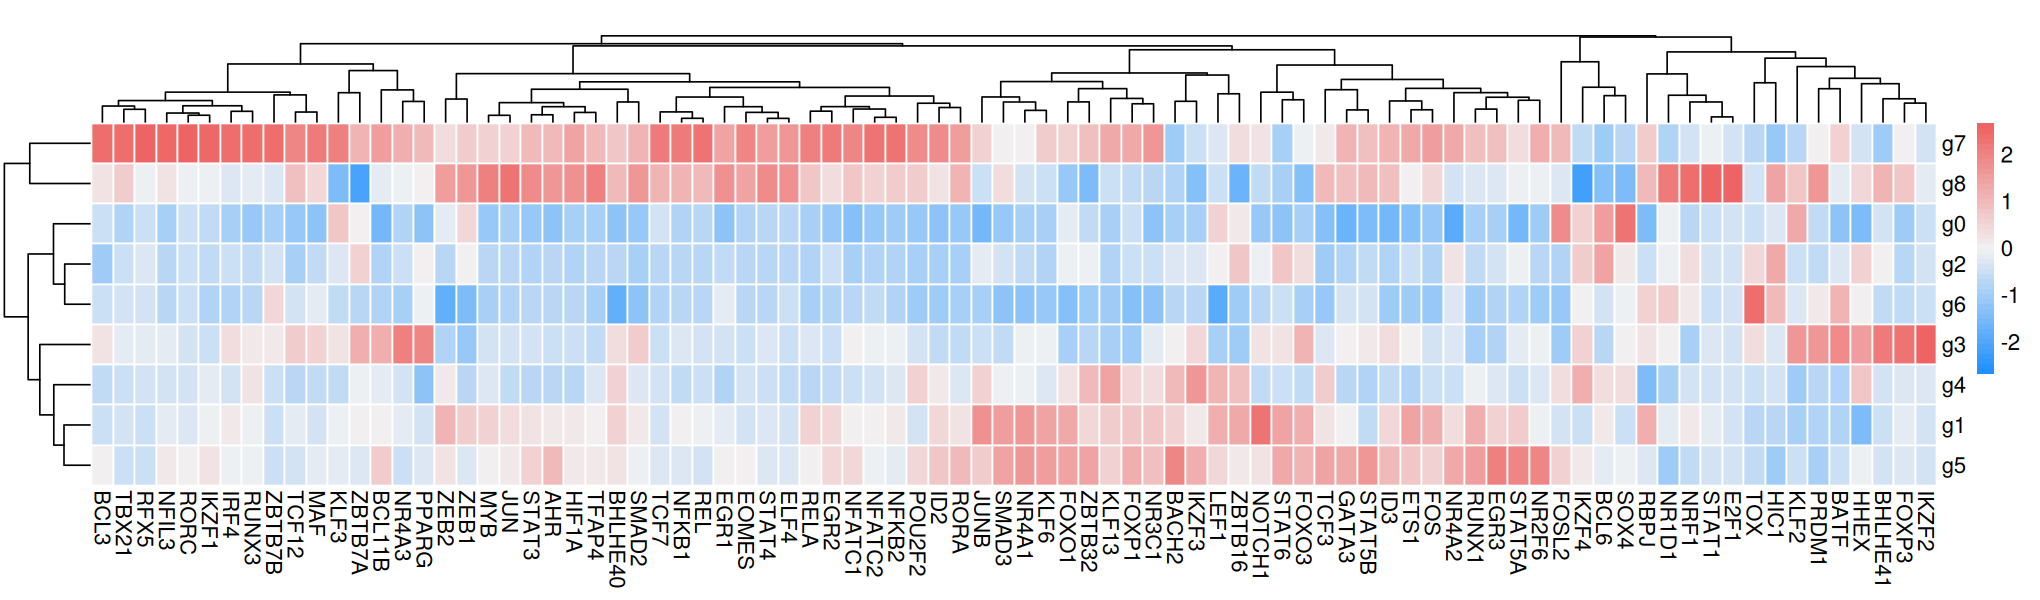

In [24]:
avgexp = AverageExpression(data, features = markers2, group.by = "seurat_clusters",
                          assay = "CollecTRI")

options(repr.plot.width = 17, repr.plot.height = 5)
    pheatmap::pheatmap(t(avgexp$CollecTRI), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 13, width = 17, height = 4)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



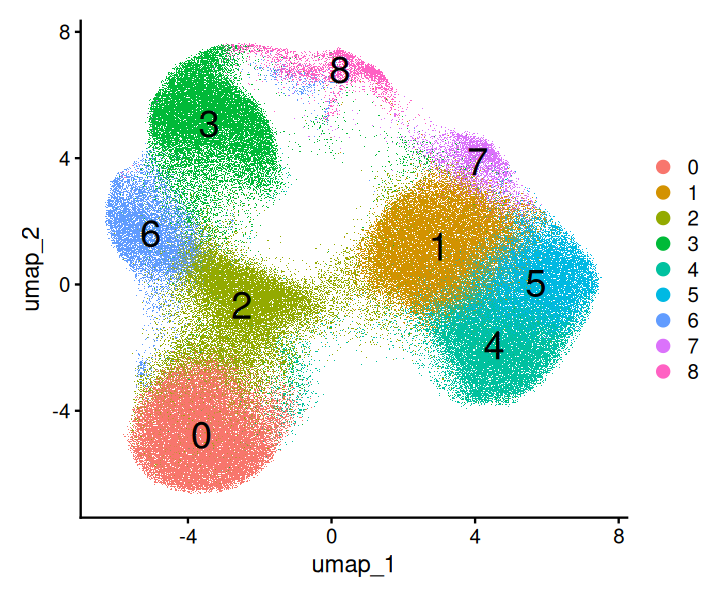

In [26]:
options(repr.plot.width = 6, repr.plot.height = 5)
DimPlot(cd4, label = T, label.size = 8)

In [30]:
markers3  <- c("BCL3","TBX21","STAT5A","IRF4","NFATC1","NFATC2","STAT1","STAT3","BATF","REL","RELA","NFIL3","RUNX3","ELF4","RORC","IKZF1","EOMES","RBPJ","BHLHE40")

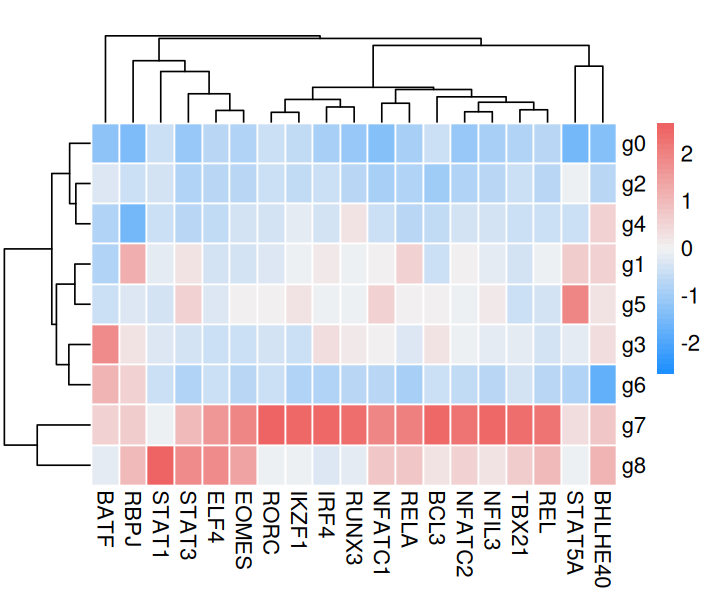

In [31]:
avgexp = AverageExpression(data, features = markers3, group.by = "seurat_clusters",
                          assay = "CollecTRI")

options(repr.plot.width = 6, repr.plot.height = 5)
    pheatmap::pheatmap(t(avgexp$CollecTRI), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 13, width = 17, height = 4)